# **2. Motivos de Cartão e Detecção de VAR: Embeddings, BERTopic e Rotulagem Semântica**

Este notebook implementa um pipeline NLP para analisar as justificativas livres de cartões amarelos e vermelhos e os motivos de acréscimos nas súmulas do Campeonato Brasileiro.

**Cartões:** identificar o *tipo de falta* por trás de cada cartão, caracterizando o perfil de marcação de cada árbitro e o padrão de infrações de cada time.

**Acréscimos/atrasos:** detectar, de forma binária, se há menção ao VAR na justificativa registrada pelo árbitro.

## Pipeline de Motivos de Cartão

1. **Embeddings base** — `multilingual-e5-large` (1024 dim) aplicado ao conjunto de textos únicos de justificativas, com prefixos `passage:` / `query:` conforme protocolo E5.
2. **Seleção de hiperparâmetros** — grid search sobre `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN) via Silhouette Score.
3. **BERTopic — Passagem 1** — clustering exploratório com o modelo base; gera pares positivos para o fine-tuning.
4. **Fine-tuning** — `MultipleNegativesRankingLoss` com pares derivados dos clusters da Passagem 1 (*self-supervised contrastive learning*, Gao et al. 2021).
5. **BERTopic — Passagem 2** — clusters finais com embeddings do modelo fine-tunado.
6. **Ablação** — comparação Pass 1 vs. Pass 2 em número de clusters, taxa de outliers e Silhouette Score.
7. **Rotulagem semântica via LLM** — `claude-haiku-4-5` classifica cada cluster (top-15 textos representativos) em grupos-semente ou propõe novos grupos; outliers HDBSCAN são classificados em batches.


## **1. Bibliotecas**

- `sentence-transformers` — embeddings semânticos e fine-tuning com `MultipleNegativesRankingLoss`
- `bertopic` — clustering temático via UMAP + HDBSCAN + c-TF-IDF
- `umap-learn` — redução de dimensionalidade antes do HDBSCAN
- `scikit-learn` — Silhouette Score como métrica de qualidade de clustering

In [74]:
import json
import re
import shutil
import unicodedata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 220)
plt.style.use("seaborn-v0_8-whitegrid")

## **2. Configuração**

Caminhos, hiperparâmetros e flags de execução. O modelo fine-tunado é reutilizado quando já existe em `models/`, evitando re-treinar em execuções subsequentes.

| Parâmetro | Valor | Descrição |
|-----------|-------|-----------|
| `MODEL_NAME` | `intfloat/multilingual-e5-large` | Modelo de embeddings — multilingual, 1024 dim |
| `MODEL_NAME_BASELINE` | `paraphrase-multilingual-mpnet-base-v2` | Modelo anterior (768 dim), mantido como referência de ablação |
| `ENCODE_PREFIX_PASSAGE` | `"passage: "` | Prefixo obrigatório para passagens no protocolo E5 |
| `ENCODE_PREFIX_QUERY` | `"query: "` | Prefixo obrigatório para consultas no protocolo E5 |
| `FINETUNE_EPOCHS` | 1 | Uma epoch evita overfitting com pares sintéticos em corpus pequeno |
| `BERTOPIC_NGRAM_RANGE` | (1, 3) | Captura expressões como "falta tática" e "ataque promissor" |
| `LLM_MODEL` | `claude-haiku-4-5-20251001` | Modelo LLM para rotulagem semântica dos clusters |
| `LLM_N_EXAMPLES` | 15 | Textos representativos enviados ao LLM por cluster |


In [75]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
VIZ_PATH = PROJECT_ROOT / "viz"
OUTPUT_DIR = PROCESSED_PATH / "semantic_reasons"
CARD_OUTPUT_DIR = OUTPUT_DIR / "card_reasons"
DELAY_OUTPUT_DIR = OUTPUT_DIR / "delay_reasons"

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
DELAY_REASONS_PATH = PROCESSED_PATH / "delay_reasons.csv"

for directory in [MODELS_DIR, OUTPUT_DIR, CARD_OUTPUT_DIR, DELAY_OUTPUT_DIR, VIZ_PATH]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

MODEL_NAME_BASELINE = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
MODEL_NAME          = "intfloat/multilingual-e5-large"
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_e5_large_two_pass"
ENCODE_PREFIX_PASSAGE = "passage: "
ENCODE_PREFIX_QUERY   = "query: "

RUN_FINE_TUNING = True
RETRAIN_FINETUNED_MODEL = False
USE_FINETUNED_IF_AVAILABLE = True
FINETUNE_EPOCHS = 1
FINETUNE_BATCH_SIZE = 32
MAX_TEXTS_PER_GROUP_FOR_FINETUNE = 220
MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE = 450

CARD_MIN_TOPIC_SIZE = 45
DELAY_MIN_TOPIC_SIZE = 35
BERTOPIC_NGRAM_RANGE = (1, 3)

CARD_TEXT_COLUMN = "card_reason_text"
CARD_TEXT_KEY_COLUMN = "card_reason_text_key"
DELAY_TEXT_COLUMN = "delay_reason_clean"

TOP_N_CARD_TEXTS = 15
TOP_N_TEAMS = 15
TOP_N_REFEREES = 15

def save_plot(fig, filename: str) -> None:
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches="tight")


## **3. Carregamento e Pré-processamento dos Dados**

Os dois arquivos de entrada são gerados no notebook 1. Para cartões, o texto de justificativa (`card_reason_text`) passa por normalização Unicode e remoção de pontuação — necessário para reduzir a fragmentação no vocabulário do BERTopic e para que variações ortográficas como "calçar" e "calcar" gerem embeddings próximos. Para atrasos, o campo `delay_reason` é mantido em forma original para análise léxica posterior.

In [76]:
REQUIRED_CARD_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "minute", "half", "reason", "reason_key",
}
REQUIRED_DELAY_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro", "delay_reason",
}

cards = pd.read_csv(CARD_REASONS_PATH, keep_default_na=False)
delays = pd.read_csv(DELAY_REASONS_PATH, keep_default_na=False)

missing_cards = REQUIRED_CARD_COLUMNS.difference(cards.columns)
missing_delays = REQUIRED_DELAY_COLUMNS.difference(delays.columns)
if missing_cards:
    raise ValueError(f"Colunas ausentes em {CARD_REASONS_PATH.name}: {sorted(missing_cards)}")
if missing_delays:
    raise ValueError(f"Colunas ausentes em {DELAY_REASONS_PATH.name}: {sorted(missing_delays)}")

cards.head(3)

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key
0,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Figueirense,7,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
1,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Guarani,15,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.


In [77]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

cards[CARD_TEXT_COLUMN] = cards["reason"].fillna("").astype(str).str.strip()
cards[CARD_TEXT_KEY_COLUMN] = cards[CARD_TEXT_COLUMN].map(normalize_text)
cards = cards[cards[CARD_TEXT_KEY_COLUMN].ne("")].reset_index(drop=True)

delays[DELAY_TEXT_COLUMN] = delays["delay_reason"].fillna("").astype(str).str.strip()
delays[DELAY_TEXT_COLUMN] = delays[DELAY_TEXT_COLUMN].where(delays[DELAY_TEXT_COLUMN].ne(""), "n/a")
delays["delay_reason_key"] = delays[DELAY_TEXT_COLUMN].map(normalize_text)

pd.Series({
    "card_rows": len(cards),
    "unique_card_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
    "delay_rows": len(delays),
    "unique_delay_reason_texts": delays["delay_reason_key"].nunique(),
    "delay_na": delays[DELAY_TEXT_COLUMN].eq("n/a").sum(),
})

card_rows                    25752
unique_card_reason_texts      6940
delay_rows                    5663
unique_delay_reason_texts     3765
delay_na                        52
dtype: int64

## **4. Análise Exploratória dos Cartões**

Volume por ano, tipo e distribuição das justificativas mais frequentes. A concentração de textos recorrentes orienta o `min_topic_size` do BERTopic: textos com centenas de ocorrências formam clusters densos; textos raros tendem a ser outliers HDBSCAN.

In [78]:
card_dataset_summary = pd.Series({
    "cards": len(cards),
    "yellow_cards": int(cards["card_type"].eq("yellow").sum()),
    "red_cards": int(cards["card_type"].eq("red").sum()),
    "teams": cards["team"].nunique(),
    "referees": cards["arbitro"].nunique(),
    "unique_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
})
card_dataset_summary

cards                  25752
yellow_cards           24573
red_cards               1179
teams                    248
referees                 173
unique_reason_texts     6940
dtype: int64

In [79]:
card_by_year_type = pd.crosstab(cards["year"], cards["card_type"])
card_by_year_type

card_type,red,yellow
year,,
2020,197,3692
2021,170,3603
2022,180,3842
2023,174,3868
2024,187,4066
2025,184,3895
2026,87,1607


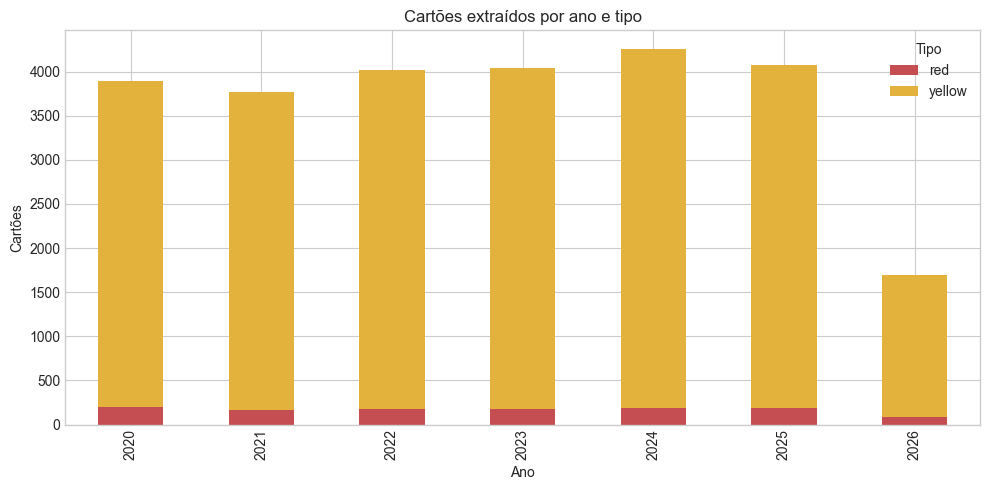

In [80]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"yellow": "#E3B23C", "red": "#C44E52"}
card_by_year_type.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[colors.get(column, "#4C78A8") for column in card_by_year_type.columns],
)
ax.set_title("Cartões extraídos por ano e tipo")
ax.set_xlabel("Ano")
ax.set_ylabel("Cartões")
ax.legend(title="Tipo")
plt.tight_layout()
save_plot(fig, "cards_by_year_type.png")
plt.show()

In [81]:
card_text_counts = (
    cards.groupby(CARD_TEXT_KEY_COLUMN)
    .agg(
        text_for_embedding=(CARD_TEXT_COLUMN, "first"),
        n_events=(CARD_TEXT_COLUMN, "size"),
        n_yellow=("card_type", lambda values: (values == "yellow").sum()),
        n_red=("card_type", lambda values: (values == "red").sum()),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
    .reset_index(drop=True)
)

card_texts = card_text_counts["text_for_embedding"].tolist()
card_text_counts.head(25)

,card_reason_text_key,text_for_embedding,n_events,n_yellow,n_red
0,por calcar seu adversario de maneira temeraria na disputa de bola,Por calçar seu adversário de maneira temerária na disputa de bola.,500,500,0
1,por cometer uma falta tatica impedindo um ataque promissor,"Por cometer uma falta tática, impedindo um ataque promissor.",410,410,0
2,por retardar o reinicio de jogo,Por retardar o reinicio de jogo,333,333,0
3,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,285,284,1
4,por cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,248,247,1
5,por calcar seu adversario de maneira temeraria na disputa da bola,"Por calçar seu adversário de maneira temerária, na disputa da bola",236,236,0
6,por calcar seu adversario de forma temeraria na disputa de bola,Por calçar seu adversário de forma temerária na disputa de bola.,228,228,0
7,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,223,1
8,por reclamar contra as decisoes da arbitragem,Por reclamar contra as decisões da arbitragem.,202,202,0
9,por impedir um ataque promissor,Por impedir um ataque promissor.,202,202,0


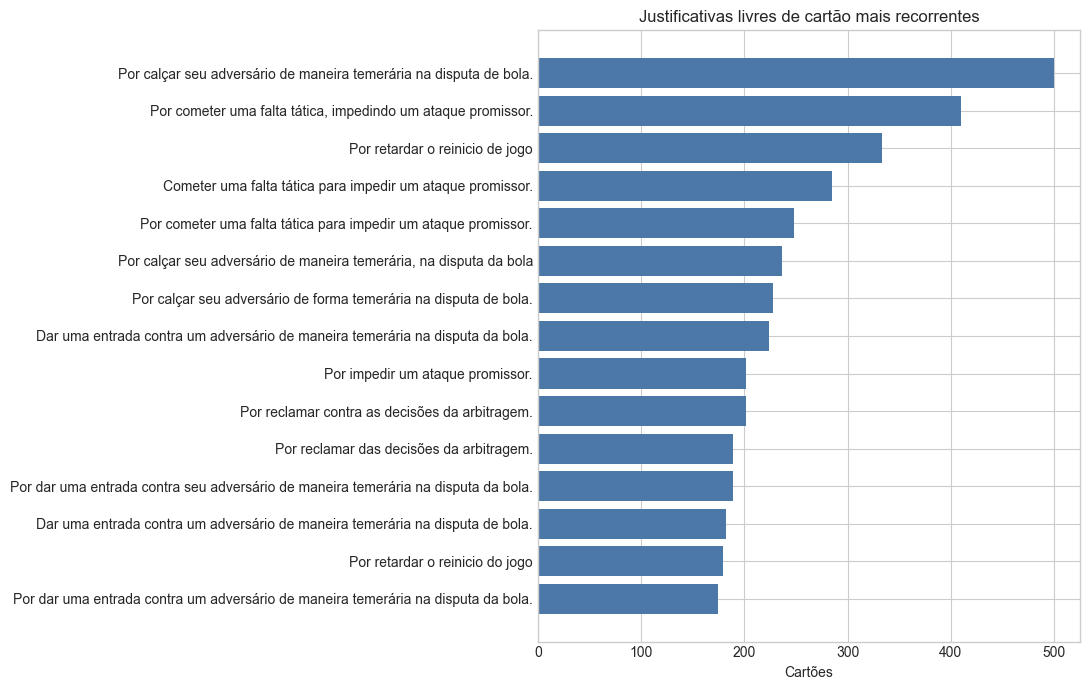

In [82]:
plot_top_texts = card_text_counts.head(TOP_N_CARD_TEXTS).sort_values("n_events")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_top_texts["text_for_embedding"], plot_top_texts["n_events"], color="#4C78A8")
ax.set_title("Justificativas livres de cartão mais recorrentes")
ax.set_xlabel("Cartões")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "top_card_reason_texts.png")
plt.show()

## **5. Funções Auxiliares**

- `make_topic_model` — cria BERTopic com `embedding_model=None` para usar embeddings pré-calculados; UMAP com `n_components=5`, `metric="cosine"` e `min_dist=0.0` conforme recomendação do BERTopic.
- `load_embedding_model` — carrega `SentenceTransformer` com fallback para transformer puro + mean pooling.
- `silhouette_no_outliers` — exclui label -1 antes do Silhouette Score; incluir outliers como pseudo-classe inflaria artificialmente a métrica.
- `build_topic_summary` — agrega contagens de eventos e termos top por cluster.
- `top_examples_by_topic` — exemplos representativos por tópico, ordenados por frequência.
- `print_cluster_inspection` — formata clusters para inspeção antes da rotulagem semântica.


In [83]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas", "foi", "foram",
    "acrescimo", "acrescimos", "devido", "inicio", "reinicio", "tempo", "minuto", "minutos", "jogadores",
}

def make_topic_model(min_topic_size: int, n_neighbors: int = 15) -> BERTopic:
    vectorizer_model = CountVectorizer(
        stop_words=list(PORTUGUESE_STOPWORDS),
        ngram_range=BERTOPIC_NGRAM_RANGE,
        min_df=2,
    )
    umap_model = umap.UMAP(n_components=5, n_neighbors=n_neighbors, min_dist=0.0, metric="cosine", random_state=RANDOM_STATE)
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        vectorizer_model=vectorizer_model,
        min_topic_size=min_topic_size,
        calculate_probabilities=False,
        verbose=False,
    )

def silhouette_no_outliers(embeddings: np.ndarray, labels, sample_size: int = 3000) -> float:
    mask = np.array(labels) != -1
    if mask.sum() < 2:
        return float('nan')
    return float(
        silhouette_score(
            embeddings[mask], np.array(labels)[mask],
            sample_size=min(sample_size, int(mask.sum())),
            random_state=RANDOM_STATE,
        )
    )

def topic_words(topic_model: BERTopic, topic_id: int, top_n: int = 8) -> str:
    if topic_id == -1:
        return "outliers"
    words = topic_model.get_topic(topic_id) or []
    return ", ".join(word for word, _ in words[:top_n])

def build_topic_summary(topic_model: BERTopic, text_counts: pd.DataFrame, topic_col: str) -> pd.DataFrame:
    topic_info = topic_model.get_topic_info().rename(columns={"Topic": topic_col})
    event_counts = (
        text_counts.groupby(topic_col)
        .agg(
            n_unique_texts=("text_for_embedding", "size"),
            n_events=("n_events", "sum"),
        )
        .reset_index()
    )
    summary = topic_info.merge(event_counts, on=topic_col, how="left")
    summary["top_terms"] = summary[topic_col].map(lambda topic_id: topic_words(topic_model, int(topic_id)))
    return summary.sort_values("n_events", ascending=False).reset_index(drop=True)

def top_examples_by_topic(text_counts: pd.DataFrame, topic_col: str, top_n: int = 5) -> pd.DataFrame:
    columns = [topic_col, "n_events", "text_for_embedding"]
    return (
        text_counts.sort_values([topic_col, "n_events"], ascending=[True, False])
        .groupby(topic_col)
        .head(top_n)
        [columns]
        .reset_index(drop=True)
    )


def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] SentenceTransformer: {path}")
        return model
    except Exception:
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Transformer + mean pooling: {path}")
        return model

def model_dir_ready(path: Path) -> bool:
    return (path / "modules.json").exists()

def print_cluster_inspection(
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 3,
) -> None:
    summary = build_topic_summary(topic_model, text_counts, topic_col)
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    print(f"{'ID':>4}  {'Eventos':>8}  Top terms")
    print("-" * 110)
    for _, row in summary.iterrows():
        topic_id = int(row[topic_col])
        n_events = int(row.get("n_events", 0))
        terms = str(row["top_terms"])
        suffix = "  [outliers HDBSCAN]" if topic_id == -1 else ""
        print(f"\n{topic_id:>4}  {n_events:>8,}  {terms}{suffix}")
        examples = examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist()
        for example in examples:
            print(f"              > {str(example)[:108]}")

## **6. Pipeline NLP — Motivos de Cartão**

Arquitetura de duas passagens: o modelo base produz clusters exploratórios que geram os pares de treino para o fine-tuning; o modelo fine-tunado produz os clusters finais usados na rotulagem semântica.

### **6.1 Embeddings Base**

`multilingual-e5-large` (1024 dim) aplicado ao conjunto de textos únicos de justificativas. O modelo exige prefixos `passage:` nos textos a indexar e `query:` nas consultas — protocolo obrigatório da família E5 para maximizar a qualidade dos embeddings.

Trabalhar sobre textos únicos — e não sobre todas as ocorrências — reduz o custo computacional do UMAP+HDBSCAN e elimina o viés de duplicatas nos embeddings de cluster.


In [84]:
base_model = load_embedding_model(MODEL_NAME)

base_card_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
base_card_embeddings = np.asarray(base_card_embeddings)
print(f"Embeddings base: {base_card_embeddings.shape}")

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 7309.40it/s]


[OK] SentenceTransformer: intfloat/multilingual-e5-large


Batches: 100%|██████████| 109/109 [00:41<00:00,  2.60it/s]

Embeddings base: (6940, 1024)


### **6.2 Seleção de Hiperparâmetros UMAP e HDBSCAN**

Os dois parâmetros com maior impacto na qualidade dos clusters são `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN), conforme documentado por Grootendorst (2022):

- **`n_neighbors`** — equilíbrio entre estrutura local e global na projeção UMAP. Valores menores criam fronteiras mais nítidas; valores maiores capturam estrutura global.
- **`min_topic_size`** — threshold de densidade do HDBSCAN; determina o número de clusters e a taxa de outliers.

`min_dist=0.0` é fixado conforme recomendação explícita do BERTopic para maximizar a densidade dos clusters. O Silhouette Score (excluindo outliers HDBSCAN) é a métrica de seleção — maior score indica clusters mais coesos no espaço original de 768 dimensões. Os resultados do grid search são salvos em CSV e reutilizados em execuções subsequentes.

Grid search base carregado do cache (grid_search_results_base_intfloat_multilingual-e5-large.csv)

Melhores parâmetros (base): n_neighbors=30, min_topic_size=15
Silhouette: 0.1222 | clusters: 113 | outliers: 1312


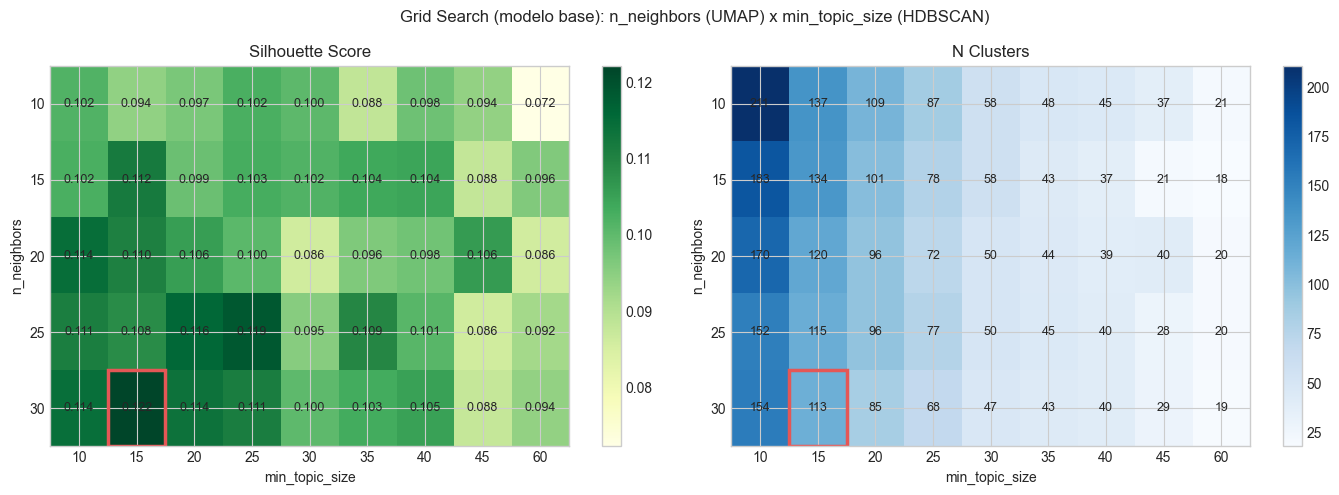

,n_neighbors,min_topic_size,n_clusters,n_outliers,outlier_pct,silhouette
0,10,10,211,1117,0.161,0.101547
1,10,15,137,1206,0.174,0.094154
2,10,20,109,1201,0.173,0.096995
3,10,25,87,1153,0.166,0.102480
4,10,30,58,733,0.106,0.100189
5,10,35,48,758,0.109,0.088195
6,10,40,45,1073,0.155,0.098248
7,10,45,37,695,0.100,0.093931
8,10,60,21,232,0.033,0.072225
9,15,10,183,1148,0.165,0.102346


In [85]:
MODEL_SLUG = MODEL_NAME.replace("/", "_")
GRID_SEARCH_BASE_PATH = OUTPUT_DIR / f"grid_search_results_base_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH = False

N_NEIGHBORS_RANGE = [10, 15, 20, 25, 30]
MIN_TOPIC_SIZE_RANGE = [10, 15, 20, 25, 30, 35, 40, 45, 60]

def _ranges_match(df: pd.DataFrame) -> bool:
    return (
        sorted(df["n_neighbors"].unique().tolist()) == sorted(N_NEIGHBORS_RANGE)
        and sorted(df["min_topic_size"].unique().tolist()) == sorted(MIN_TOPIC_SIZE_RANGE)
    )

def _run_grid_search(embeddings: np.ndarray, label: str) -> pd.DataFrame:
    combos = [(n, m) for n in N_NEIGHBORS_RANGE for m in MIN_TOPIC_SIZE_RANGE]
    results = []
    for i, (n_nb, mts) in enumerate(combos):
        _m = make_topic_model(mts, n_neighbors=n_nb)
        _topics, _ = _m.fit_transform(card_texts, embeddings=embeddings)
        _n_clusters = len(set(_topics) - {-1})
        _n_outliers = int((np.array(_topics) == -1).sum())
        _sil = silhouette_no_outliers(embeddings, _topics)
        results.append({"n_neighbors": n_nb, "min_topic_size": mts,
                         "n_clusters": _n_clusters, "n_outliers": _n_outliers,
                         "outlier_pct": round(_n_outliers / len(_topics), 3), "silhouette": _sil})
        print(f"  [{i+1:2d}/{len(combos)}] n_neighbors={n_nb:2d} | min_topic_size={mts:2d} | clusters={_n_clusters:3d} | outliers={_n_outliers:4d} | silhouette={float(_sil):.4f}")
    return pd.DataFrame(results)

if not RERUN_GRID_SEARCH and GRID_SEARCH_BASE_PATH.exists():
    grid_df = pd.read_csv(GRID_SEARCH_BASE_PATH)
    if not _ranges_match(grid_df):
        print("Ranges alterados — re-executando grid search base...")
        RERUN_GRID_SEARCH = True
    else:
        print(f"Grid search base carregado do cache ({GRID_SEARCH_BASE_PATH.name})")

if RERUN_GRID_SEARCH or not GRID_SEARCH_BASE_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo base)...")
    grid_df = _run_grid_search(base_card_embeddings, "base")
    grid_df.to_csv(GRID_SEARCH_BASE_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_BASE_PATH}")

valid_grid = grid_df.dropna(subset=["silhouette"])
best_row = valid_grid.loc[valid_grid["silhouette"].idxmax()]
best_n_neighbors = int(best_row["n_neighbors"])
best_min_topic_size = int(best_row["min_topic_size"])
print(f"\nMelhores parâmetros (base): n_neighbors={best_n_neighbors}, min_topic_size={best_min_topic_size}")
print(f"Silhouette: {best_row['silhouette']:.4f} | clusters: {int(best_row['n_clusters'])} | outliers: {int(best_row['n_outliers'])}")

sil_pivot = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="silhouette")
nc_pivot  = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="n_clusters")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pivot, title, cmap in zip(
    axes, [sil_pivot, nc_pivot], ["Silhouette Score", "N Clusters"], ["YlGn", "Blues"],
):
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(MIN_TOPIC_SIZE_RANGE)))
    ax.set_xticklabels(MIN_TOPIC_SIZE_RANGE)
    ax.set_yticks(range(len(N_NEIGHBORS_RANGE)))
    ax.set_yticklabels(N_NEIGHBORS_RANGE)
    ax.set_xlabel("min_topic_size")
    ax.set_ylabel("n_neighbors")
    ax.set_title(title)
    for ii in range(len(N_NEIGHBORS_RANGE)):
        for jj in range(len(MIN_TOPIC_SIZE_RANGE)):
            val = pivot.iloc[ii, jj]
            ax.text(jj, ii, f"{val:.3f}" if title == "Silhouette Score" else str(int(val)), ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax)
    best_i = N_NEIGHBORS_RANGE.index(best_n_neighbors)
    best_j = MIN_TOPIC_SIZE_RANGE.index(best_min_topic_size)
    ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="#E45756", linewidth=2.5))

plt.suptitle("Grid Search (modelo base): n_neighbors (UMAP) x min_topic_size (HDBSCAN)", fontsize=12)
plt.tight_layout()
save_plot(fig, "umap_param_grid_search_base.png")
plt.show()
grid_df

### **6.3 BERTopic — Passagem 1 (Exploração)**

Clustering com o modelo base. Os tópicos encontrados **não** são os rótulos finais — servem exclusivamente como fonte de pares positivos para o fine-tuning. Textos no mesmo cluster HDBSCAN formam pares semanticamente coerentes; outliers (label -1) são descartados por não pertencerem a nenhum grupo denso.

In [86]:
card_topic_model_pass1 = make_topic_model(best_min_topic_size, n_neighbors=best_n_neighbors)
card_topics_pass1, _ = card_topic_model_pass1.fit_transform(card_texts, embeddings=base_card_embeddings)
card_text_counts["bertopic_topic_pass1"] = card_topics_pass1

n_clusters_pass1 = len(set(card_topics_pass1) - {-1})
n_outliers_pass1 = int((np.array(card_topics_pass1) == -1).sum())
sil_pass1 = silhouette_no_outliers(base_card_embeddings, card_topics_pass1)

pass1_counts = card_text_counts.rename(columns={"bertopic_topic_pass1": "bertopic_topic"})
pass1_summary = build_topic_summary(card_topic_model_pass1, pass1_counts, "bertopic_topic")
pass1_summary = pass1_summary.rename(columns={"bertopic_topic": "bertopic_topic_pass1"})

print(f"Pass 1 — clusters: {n_clusters_pass1} | outliers: {n_outliers_pass1} ({100*n_outliers_pass1/len(card_topics_pass1):.1f}%) | silhouette: {sil_pass1:.4f}")
pass1_summary.head(20)

Pass 1 — clusters: 113 | outliers: 1312 (18.9%) | silhouette: 0.1222


,bertopic_topic_pass1,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,-1,1312,-1_expulsei_após_cartão_vermelho,"[expulsei, após, cartão, vermelho, cartão vermelho, expulso, arbitragem, direto, mesmo, vermelho direto]","[Expulsei de campo apresentando cartão vermelho direto, o senhor bruno mendez cittadini nº 25, da equipe do s.c. corinthians pelo mesmo dar uma entrada contra um adversário com uso de força excessiva na tentativa de ...",1312,3043,outliers
1,13,94,13_calçar adversário temerária_temerária calçar_temerária calçar adversário_adversário temerária calçar,"[calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, calçar, calçar adversário, adversário temerária, calçar temerária adversário, calçar temerária, temerária adve...","[Por calçar o seu adversário de maneira temerária na disputa da bola., Por calçar seu adversário na disputa de bola de forma temerária., Por calçar o adversário de maneira temerária na disputa da bola.]",94,2091,"calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, calçar, calçar adversário, adversário temerária, calçar temerária adversário"
2,15,84,15_entrada temerária_entrada_adversário dar entrada_entrada temerária adversário,"[entrada temerária, entrada, adversário dar entrada, entrada temerária adversário, dar entrada, dar entrada temerária, temerária adversário dar, adversário dar, temerária adversário, dar]","[Por dar uma entrada de forma temerária no adversário, na disputa da bola., Por dar uma entrada temerária no seu adversário na disputa da bola., Por dar uma entrada temerária contra seu adversário na disputa pela bola.]",84,1338,"entrada temerária, entrada, adversário dar entrada, entrada temerária adversário, dar entrada, dar entrada temerária, temerária adversário dar, adversário dar"
3,10,100,10_temerária calçar_calçar_adversário temerária calçar_temerária calçar adversário,"[temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária, adversário temerária, temerária calçar temerária]","[Calçar seu adversário na disputa de bola de maneira temerária., Calçar o adversário de forma temerária da disputa da bola, Calçar seu adversário de maneira temerária, na disputa da bola.]",100,1042,"temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, adversário calçar, calçar temerária"
4,32,62,32_ataque promissor cometer_promissor cometer_promissor cometer falta_tática,"[ataque promissor cometer, promissor cometer, promissor cometer falta, tática, cometer falta, falta tática, falta, cometer, ataque, ataque promissor]","[Por cometer uma falta tática e impedir um ataque promissor., Por cometer uma falta tática para impedir um ataque promissor., Por cometer uma falta tática para impedir uma ataque promissor.]",62,882,"ataque promissor cometer, promissor cometer, promissor cometer falta, tática, cometer falta, falta tática, falta, cometer"
5,17,77,17_retardar_substituição_reinício_reinício retardar,"[retardar, substituição, reinício, reinício retardar, retardar reinício, substituição retardar, momento substituição, retardar reinício retardar, momento substituição retardar, retardar momento]","[Por retardar o reinício do jogo em uma substituição., Por retardar o reinício de jogo durante uma substituição, Por retardar o reinício de jogo em uma substituição.]",77,881,"retardar, substituição, reinício, reinício retardar, retardar reinício, substituição retardar, momento substituição, retardar reinício retardar"
6,24,74,24_arbitragem reclamar_arbitragem protestar_arbitragem_reclamar,"[arbitragem reclamar, arbitragem protestar, arbitragem, reclamar, decisões arbitragem reclamar, decisões, decisões arbitragem, arbitragem reclamação, arbitragem reclamar decisões, protestar]","[Reclamar contra

### **6.4 Fine-Tuning do Sentence Transformer**

`MultipleNegativesRankingLoss` trata cada par `(âncora, positivo)` no batch como positivo; os demais positivos no mesmo batch atuam como negativos implícitos. Esta formulação — usada em dense retrieval (Karpukhin et al., 2020) e contrastive learning de sentenças (Gao et al., 2021 / SimCSE) — é eficiente computacionalmente e adequada para corpus pequeno com vocabulário especializado.

A geração automática de pares a partir dos clusters do BERTopic é uma forma de *self-supervised contrastive learning*: a própria estrutura semântica descoberta na Passagem 1 fornece o sinal de supervisão, sem necessidade de rótulos manuais.

In [87]:
def build_pairs_from_labels(
    text_counts: pd.DataFrame,
    labels,
    max_texts: int = MAX_TEXTS_PER_GROUP_FOR_FINETUNE,
    max_pairs: int = MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE,
    prefix: str = "",
) -> list[dict]:
    df = text_counts.copy()
    df["_label"] = labels
    pairs: list[dict] = []
    for lbl, group in df.groupby("_label"):
        if int(lbl) == -1:
            continue
        texts = (
            group.sort_values("n_events", ascending=False)["text_for_embedding"]
            .dropna().astype(str).str.strip()
            .loc[lambda s: s.ne("")]
            .drop_duplicates()
            .head(max_texts)
            .tolist()
        )
        pairs.extend(
            {"anchor": prefix + a, "positive": prefix + b}
            for a, b in list(combinations(texts, 2))[:max_pairs]
        )
    return pairs

if RUN_FINE_TUNING:
    if USE_FINETUNED_IF_AVAILABLE and model_dir_ready(FINETUNED_MODEL_DIR) and not RETRAIN_FINETUNED_MODEL:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando.")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        import datasets as hf_datasets
        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers
        import sentence_transformers.base.trainer as st_base_trainer

        if not hasattr(st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as TorchIterableDataset
            st_base_trainer.IterableDataset = TorchIterableDataset

        if FINETUNED_MODEL_DIR.exists() and RETRAIN_FINETUNED_MODEL:
            shutil.rmtree(FINETUNED_MODEL_DIR)

        positive_pairs = build_pairs_from_labels(
            card_text_counts, card_topics_pass1, prefix=ENCODE_PREFIX_PASSAGE
        )
        n_outlier_texts = int((np.array(card_topics_pass1) == -1).sum())
        if not positive_pairs:
            raise ValueError("Nenhum par positivo gerado pelo BERTopic Pass 1.")
        print(f"Pares positivos gerados (BERTopic Pass 1): {len(positive_pairs):,}")
        print(f"Textos outlier excluídos: {n_outlier_texts}")

        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)
        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)
        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=FINETUNE_EPOCHS,
            per_device_train_batch_size=FINETUNE_BATCH_SIZE,
            learning_rate=2e-5,
            warmup_ratio=0.1,
            fp16=False,
            use_cpu=True,
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )
        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()
        ft_model.save(str(FINETUNED_MODEL_DIR))
        embedding_model = ft_model
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
else:
    embedding_model = base_model
    print("Fine-tuning desabilitado. Usando modelo base.")

print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")


Modelo fine-tunado encontrado em /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass. Carregando.


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 8027.95it/s]


[OK] SentenceTransformer: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_e5_large_two_pass
Dimensão dos embeddings: 1024


### **6.5 BERTopic — Passagem 2 (Clusters Finais)**

O modelo fine-tunado gera embeddings com maior separabilidade intra-domínio. Um segundo grid search é executado sobre os embeddings fine-tunados — os hiperparâmetros ótimos podem diferir dos da Passagem 1, pois a geometria do espaço de embeddings muda após o fine-tuning.

In [88]:
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings de cartões: {card_embeddings.shape}")

Batches: 100%|██████████| 109/109 [00:38<00:00,  2.85it/s]

Embeddings de cartões: (6940, 1024)


In [89]:
GRID_SEARCH_FT_PATH = OUTPUT_DIR / f"grid_search_results_ft_{MODEL_SLUG}.csv"
RERUN_GRID_SEARCH_FT = RETRAIN_FINETUNED_MODEL

if not RERUN_GRID_SEARCH_FT and GRID_SEARCH_FT_PATH.exists():
    grid_ft_df = pd.read_csv(GRID_SEARCH_FT_PATH)
    if not _ranges_match(grid_ft_df):
        print("Ranges alterados — re-executando grid search FT...")
        RERUN_GRID_SEARCH_FT = True
    else:
        print(f"Grid search FT carregado do cache ({GRID_SEARCH_FT_PATH.name})")

if RERUN_GRID_SEARCH_FT or not GRID_SEARCH_FT_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo fine-tunado)...")
    grid_ft_df = _run_grid_search(card_embeddings, "ft")
    grid_ft_df.to_csv(GRID_SEARCH_FT_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_FT_PATH}")

valid_ft = grid_ft_df.dropna(subset=["silhouette"])
best_row_ft = valid_ft.loc[valid_ft["silhouette"].idxmax()]
best_n_neighbors_ft = int(best_row_ft["n_neighbors"])
best_min_topic_size_ft = int(best_row_ft["min_topic_size"])
print(f"\nMelhores parâmetros (fine-tunado): n_neighbors={best_n_neighbors_ft}, min_topic_size={best_min_topic_size_ft}")
print(f"Silhouette: {best_row_ft['silhouette']:.4f} | clusters: {int(best_row_ft['n_clusters'])} | outliers: {int(best_row_ft['n_outliers'])}")

Grid search FT carregado do cache (grid_search_results_ft_intfloat_multilingual-e5-large.csv)

Melhores parâmetros (fine-tunado): n_neighbors=30, min_topic_size=25
Silhouette: 0.4658 | clusters: 101 | outliers: 380


In [90]:
card_topic_model = make_topic_model(best_min_topic_size_ft, n_neighbors=best_n_neighbors_ft)
card_topics, _ = card_topic_model.fit_transform(card_texts, embeddings=card_embeddings)
card_text_counts["bertopic_topic"] = card_topics

n_clusters_pass2 = len(set(card_topics) - {-1})
n_outliers_pass2 = int((np.array(card_topics) == -1).sum())
sil_pass2 = silhouette_no_outliers(card_embeddings, card_topics)

card_topic_summary = build_topic_summary(card_topic_model, card_text_counts, "bertopic_topic")
print(f"Pass 2 — clusters: {n_clusters_pass2} | outliers: {n_outliers_pass2} ({100*n_outliers_pass2/len(card_topics):.1f}%) | silhouette: {sil_pass2:.4f}")
card_topic_summary.head(20)

Pass 2 — clusters: 102 | outliers: 334 (4.8%) | silhouette: 0.4494


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,9,107,9_calçar_calçar adversário temerária_calçar adversário_temerária calçar,"[calçar, calçar adversário temerária, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária, adversário calçar adversário, calçar temer...","[Por calçar seu adversário na disputa de bola de forma temerária., Por calçar o seu adversário de maneira temerária na disputa de bola., Por calçar o seu adversário de forma temerária na disputa de bola.]",107,2147,"calçar, calçar adversário temerária, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária"
1,11,105,11_entrada temerária_entrada_dar entrada_dar entrada temerária,"[entrada temerária, entrada, dar entrada, dar entrada temerária, entrada temerária adversário, adversário dar entrada, temerária dar entrada, temerária adversário dar, temerária adversário, adversário dar]","[Por dar uma entrada temerária em seu adversário na disputa da jogada, Por dar um entrada de maneira temerária no seu adversário na disputa da bola., Ao dar uma entrada de maneira temerária em seu adversário na dispu...",105,1350,"entrada temerária, entrada, dar entrada, dar entrada temerária, entrada temerária adversário, adversário dar entrada, temerária dar entrada, temerária adversário dar"
2,12,101,12_temerária calçar_calçar_adversário temerária calçar_temerária calçar adversário,"[temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, calçar temerária, adversário calçar, temerária calçar temerária, calçar temerária c...","[Calçar seu adversário na disputa da bola de maneira temerária., Calçar o adversário de maneira temerária., Calçar seu adversário de maneira temerária.]",101,1050,"temerária calçar, calçar, adversário temerária calçar, temerária calçar adversário, calçar adversário temerária, calçar adversário, calçar temerária, adversário calçar"
3,-1,334,-1_reclamar_protestar_arbitragem_cobrança falta,"[reclamar, protestar, arbitragem, cobrança falta, adverti, decisões arbitragem, decisões, respeitar, não respeitar, cobrança]","[Por não respeitar a distância regulamentar no tiro livre direto., Por não respeitar a distância regulamentar de um tiro livre., Não respeitar a distância regulamentar em um tiro livre.]",334,1042,outliers
4,19,93,19_retardar_reinício_substituição_retardar reinício,"[retardar, reinício, substituição, retardar reinício, reinício retardar, retardar retardar, substituição retardar, reposição, momento substituição, retardar reinício retardar]","[Por retardar o reinício de jogo em uma substituição., Por retardar o reinício do jogo em uma substituição., Por retardar o reinício de jogo durante uma substituição]",93,898,"retardar, reinício, substituição, retardar reinício, reinício retardar, retardar retardar, substituição retardar, reposição"
5,49,63,49_ataque promissor cometer_promissor cometer_promissor cometer falta_cometer falta,"[ataque promissor cometer, promissor cometer, promissor cometer falta, cometer falta, falta, tática, cometer, falta tática, ataque, ataque promissor]","[Advertido por cometer uma falta tática impedindo um ataque promissor., Advertido por cometer falta tática impedindo ataque promissor., Por cometer uma falta tática impedindo uma ataque promissor.]",63,887,"ataque promissor cometer, promissor cometer, promissor cometer falta, cometer falta, falta, tática, cometer, falta tática"
6,13,98,13_dar entrada_entrada_entrada temerária_dar entrada temerária,"[dar entrada, entrada, entrada temerária, dar entrada temerária, adversário dar entrada, temerária dar entrada, dar entrada adversário, entrada adversário, dar, entrada temerária adversário]","[Dar uma entrada temerária contra seu adversário, na disputa da bola., Dar uma entrada de maneira temerária contr

In [91]:
card_topic_examples = top_examples_by_topic(card_text_counts, "bertopic_topic", top_n=5)
card_topic_examples.head(30)

,bertopic_topic,n_events,text_for_embedding
0,-1,202,Por impedir um ataque promissor.
1,-1,67,Reclamar contra as decisões da arbitragem
2,-1,30,Reclamar das decisões da arbitragem
3,-1,29,"Por dar uma entrada temerária contra seu adversário, na disputa da bola."
4,-1,25,Por dar uma entrada temerária contra seu adversário na disputa de bola.
5,0,2,"Por desferir dois tapas, um no braço e outro nas costas do seu adversario de nº 03, sr. rodrigo caio coquette russo, fora da disputa da bola. o atleta atingido continuou no jogo normalmente. o atleta expulso deixou o..."
6,0,2,Por dar uma entrada em seu adversário fernando canesin matos com as travas da chuteira na altura do tornozelo na disputa pela bola colocando em risco a integridade física do mesmo.
7,0,2,"Por desferir uma cotovelada atingindo o rosto do seu adversário senhor angelo giovani araos llanos, número 21, fora da disputa da bola com uso de força excessiva. o atleta atingido necessitou de atendimento médico e ..."
8,0,2,"Por desferir um tapa no rosto de seu adversário de número 18, sr matheus de vargas após a marcação de uma falta a favor de sua equipe. ."
9,0,2,"Por chutar a perna de seu adversário, atingindo a pantorrilha do mesmo com uso de força excessiva, quando a bola estava fora de jogo, informo que o atleta atingido continuou na partida e o atleta expulso saiu sem ami..."


### **6.6 Ablação: Modelo Base vs. Fine-Tunado**

Comparação direta entre Pass 1 (modelo base) e Pass 2 (modelo fine-tunado) usando os hiperparâmetros ótimos de cada passagem. As métricas — número de clusters, taxa de outliers e Silhouette Score — quantificam o ganho do fine-tuning na separabilidade semântica dos embeddings.

O modelo baseline (`paraphrase-multilingual-mpnet-base-v2`, 768 dim) foi avaliado na mesma configuração e serviu de referência para a adoção do `multilingual-e5-large`.


Ganho de silhouette: +267.7%


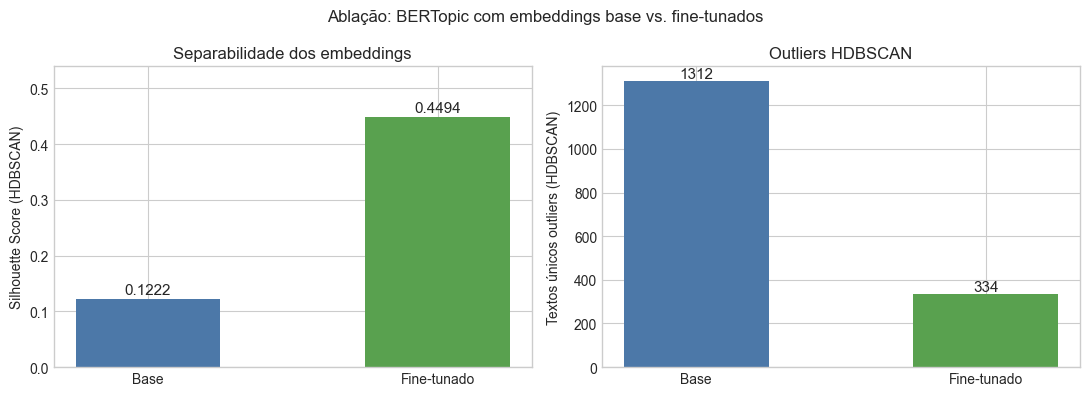

,Passagem,n_neighbors,min_topic_size,N Clusters,Outliers,Outlier %,Silhouette Score
0,Pass 1 — Modelo base,30,15,113,1312,18.9%,0.1222
1,Pass 2 — Fine-tunado,30,25,102,334,4.8%,0.4494


In [92]:
outlier_pct_pass1 = 100 * n_outliers_pass1 / len(card_topics_pass1)
outlier_pct_pass2 = 100 * n_outliers_pass2 / len(card_topics)
sil_gain = (sil_pass2 - sil_pass1) / sil_pass1 * 100

ablation_table = pd.DataFrame({
    "Passagem": ["Pass 1 — Modelo base", "Pass 2 — Fine-tunado"],
    "n_neighbors": [best_n_neighbors, best_n_neighbors_ft],
    "min_topic_size": [best_min_topic_size, best_min_topic_size_ft],
    "N Clusters": [n_clusters_pass1, n_clusters_pass2],
    "Outliers": [n_outliers_pass1, n_outliers_pass2],
    "Outlier %": [f"{outlier_pct_pass1:.1f}%", f"{outlier_pct_pass2:.1f}%"],
    "Silhouette Score": [round(sil_pass1, 4), round(sil_pass2, 4)],
})
print(f"Ganho de silhouette: +{sil_gain:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["Base", "Fine-tunado"]
colors = ["#4C78A8", "#59A14F"]

axes[0].bar(labels, [sil_pass1, sil_pass2], color=colors, width=0.5)
for ax_bar, val in zip(axes[0].patches, [sil_pass1, sil_pass2]):
    axes[0].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.003, f"{val:.4f}", ha="center", va="bottom", fontsize=11)
axes[0].set_ylabel("Silhouette Score (HDBSCAN)")
axes[0].set_title("Separabilidade dos embeddings")
axes[0].set_ylim(0, max(sil_pass1, sil_pass2) * 1.2)

axes[1].bar(labels, [n_outliers_pass1, n_outliers_pass2], color=colors, width=0.5)
for ax_bar, val in zip(axes[1].patches, [n_outliers_pass1, n_outliers_pass2]):
    axes[1].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.5, str(val), ha="center", va="bottom", fontsize=11)
axes[1].set_ylabel("Textos únicos outliers (HDBSCAN)")
axes[1].set_title("Outliers HDBSCAN")

plt.suptitle("Ablação: BERTopic com embeddings base vs. fine-tunados", fontsize=12)
plt.tight_layout()
save_plot(fig, "ablation_silhouette.png")
plt.show()
ablation_table

## **7. Rotulagem Semântica dos Clusters via LLM**

O BERTopic (Passagem 2) agrupa textos em clusters de alta coesão semântica. A etapa de rotulagem mapeia cada cluster para um **grupo interpretável de infrações disciplinares**, fundamentado na Lei 12 do IFAB (*Fouls and Misconduct*) e adaptado ao vocabulário das súmulas CBF.

### Arquitetura do pipeline

- Para cada cluster, os **15 textos mais frequentes** são enviados ao Haiku como amostra representativa
- O LLM escolhe entre **19 grupos-semente** com descrições precisas (incluindo sinais positivos e fronteiras com grupos vizinhos)
- Outliers do HDBSCAN (cluster `-1`) são classificados individualmente em batches de 15
- Resultados são **cacheados em CSV** — re-execuções pulam itens já rotulados
- Se o LLM propõe um `NOVO:` grupo, o notebook exibe os exemplos para **revisão humana** antes de resolver o mapeamento

### Taxonomia de grupos (Lei 12 IFAB + prática CBF)

| Grupo | Base legal |
|---|---|
| Falta temerária em disputa de bola | Reckless challenge — cartão amarelo |
| Jogo brusco grave | Serious foul play / Violent conduct — cartão vermelho |
| Falta tática em ataque promissor | PAAOGG — cartão amarelo |
| Impedir clara oportunidade de gol | DOGSO — cartão vermelho |
| Toque de mão na bola | Handling — depende do contexto |
| Protesto ou reclamação contra a arbitragem | Dissent — cartão amarelo |
| Insubordinação da comissão técnica | Team official misconduct |
| Retardar reinício do jogo | Delaying restart — cartão amarelo |
| Não respeitar o local de saída em substituição | Delaying restart (substituição) |
| Agarrar ou puxar o adversário | Unsporting behaviour |
| Infração persistente às regras | Persistent offences — cartão amarelo |
| Comemoração irregular | Unsporting behaviour (comemoração) |
| Entrar, reentrar ou deixar o campo sem autorização | Entering field without permission |
| Gesto ou linguagem ofensiva | Offensive/abusive language — cartão vermelho |
| Confronto físico ou verbal | Violent conduct / unsporting behaviour |
| Simulação de falta | Deceiving the referee (feigning) |
| Não respeitar distância regulamentar em cobranças | Failing required distance |
| Dano a equipamento | Violent conduct (object) |
| Conduta antidesportiva | Unsporting behaviour (catch-all) |

### Score de representatividade

Após a rotulagem, um **score de representatividade** por texto é calculado como a similaridade cosseno entre o embedding do texto e o centroide ponderado (por `n_events`) do seu grupo. Score próximo de 1 = texto muito central no grupo; score baixo = texto na fronteira ou potencialmente mal classificado.


In [93]:
print_cluster_inspection(card_topic_model, card_text_counts, "bertopic_topic")

  ID   Eventos  Top terms
--------------------------------------------------------------------------------------------------------------

   9     2,147  calçar, calçar adversário temerária, calçar adversário, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário temerária
              > Por calçar seu adversário de maneira temerária na disputa de bola.
              > Por calçar seu adversário de maneira temerária, na disputa da bola
              > Por calçar seu adversário de forma temerária na disputa de bola.

  11     1,350  entrada temerária, entrada, dar entrada, dar entrada temerária, entrada temerária adversário, adversário dar entrada, temerária dar entrada, temerária adversário dar
              > Por dar uma entrada em seu adversário de maneira temerária na disputa de bola.
              > Por dar uma entrada temerária em seu adversário na disputa de bola.
              > Por dar uma entrada temerária em seu adversário n

In [94]:
from dotenv import load_dotenv
load_dotenv(PROJECT_ROOT / ".env")

import anthropic
import os
import re as _re
import time

LLM_MODEL = "claude-haiku-4-5-20251001"
LLM_N_EXAMPLES = 15
LLM_CLUSTER_CACHE_PATH = CARD_OUTPUT_DIR / "llm_cluster_labels.csv"
LLM_OUTLIER_CACHE_PATH = CARD_OUTPUT_DIR / "llm_outlier_labels.csv"
LLM_OUTLIER_BATCH_SIZE = 15

# Grupos baseados na Lei 12 IFAB (2025/26) adaptados ao vocabulário das sumulas CBF.
# Cada descricao inclui: sinais textuais (SINAL), exclusoes (NAO usar) e fronteiras.
SEED_GROUPS: dict[str, str] = {
    "Falta temerária em disputa de bola": (
        "Infraicao reckless durante disputa direta pela bola - forca alem da necessaria, "
        "sem intencao deliberada de machucar. Inclui: calcar, rasteira, tranco, carrinho, "
        "dar entrada, pontape ou chute de maneira temeraria NA DISPUTA DE BOLA. "
        "INCLUI tambem uso temerario do braco, cotovelo ou mao para atingir o adversario "
        "DURANTE a disputa de bola (golpear/atingir com o braco de maneira temeraria na disputa). "
        "SINAL: texto contem 'temeraria' + acao fisica + 'na disputa de bola' (ou equivalente). "
        "NAO usar quando o contato e fora de qualquer disputa (ver Jogo brusco grave). "
        "NAO usar quando e toque na bola com a mao (ver Toque de mao na bola)."
    ),
    "Jogo brusco grave": (
        "Uso de forca excessiva ou brutalidade - violencia fisica FORA ou independente de "
        "disputa direta pela bola. Inclui: tapas, socos, cotoveladas deliberadas fora da disputa, "
        "pisar intencionalmente, emurroes com jogo paralisado, carga violenta sem bola. "
        "SINAL: violencia deliberada, ou emurroes/contato fisico agressivo SEM o elemento "
        "'disputa da bola'; jogo paralisado + contato fisico. "
        "NAO usar para falta na disputa de bola (ver Falta temeraria em disputa de bola). "
        "NAO usar para discussao verbal sem contato fisico (ver Confronto fisico ou verbal)."
    ),
    "Falta tática em ataque promissor": (
        "Falta cometida para interromper ataque promissor - a equipe adversaria criava uma "
        "oportunidade de gol, mas NAO era uma oportunidade clara e manifesta. "
        "Inclui: segurar, agarrar, calcar, cometer falta por motivo tatico para afastar o "
        "adversario da bola. "
        "SINAL: texto contem 'ataque promissor', 'falta tatica', 'motivo tatico', 'afasta-lo'. "
        "NAO usar quando o texto menciona 'oportunidade clara de gol' "
        "(ver Impedir clara oportunidade de gol)."
    ),
    "Impedir clara oportunidade de gol": (
        "Infraicao que nega oportunidade clara e manifesta de marcar gol (DOGSO - Denying an "
        "Obvious Goal-Scoring Opportunity): falta, agarrao ou mao que impede adversario a "
        "caminho inequivoco do gol. "
        "SINAL: texto contem 'oportunidade clara', 'clara e manifesta de gol'. "
        "DISTINTO de falta tatica: aqui a oportunidade era iminente e clara, nao apenas um "
        "ataque em desenvolvimento."
    ),
    "Toque de mão na bola": (
        "Infraicao por uso proibido das maos ou bracos para jogar a bola. "
        "Inclui: bloquear chute ou arremate com a mao/braco, tocar a bola com a mao de forma "
        "proibida, colocar a mao na bola impedindo jogada. "
        "O ELEMENTO CENTRAL e contato mao/braco com a BOLA, nao com o adversario. "
        "NAO usar quando o braco atinge o adversario "
        "(ver Falta temeraria em disputa de bola ou Jogo brusco grave)."
    ),
    "Protesto ou reclamação contra a arbitragem": (
        "JOGADOR (nao comissao tecnica) que reclama, protesta ou desaprova decisoes da "
        "arbitragem com palavras, gestos ou acoes. Inclui: reclamar, protestar, desaprovar "
        "com palavras/gestos, reclamar acintosa/ostensivamente, reclamar apos o termino da "
        "partida ou durante revisao VAR. "
        "SINAL: texto menciona 'arbitragem'/'decisoes' + 'reclamar'/'protestar'/'desaprovar'. "
        "Se o cartao e para JOGADOR -> use este grupo. "
        "Se o cartao e para membro da COMISSAO TECNICA -> use Insubordinacao da comissao tecnica."
    ),
    "Insubordinação da comissão técnica": (
        "Membro da comissao tecnica (tecnico, preparador, medico, roupeiro) que infringe regras "
        "de conduta: protestar contra a arbitragem, sair da area tecnica, nao respeitar os "
        "limites da area tecnica, adentrar o campo sem autorizacao, xingar do banco de reservas. "
        "SINAL: texto menciona 'area tecnica', 'banco de reservas', ou o infrator e membro da comissao. "
        "Use SOMENTE quando o infrator e membro da COMISSAO TECNICA, nao um jogador."
    ),
    "Retardar reinício do jogo": (
        "Atrasar deliberadamente o reinicio do jogo apos paralisacao. Inclui: chutar a bola "
        "para longe apos o apito, segurar a bola com as maos para ganhar tempo, demorar "
        "excessivamente na execucao de tiro de meta, tiro livre ou arremesso lateral. "
        "SINAL: texto contem 'retardar', 'reinicio', 'chutar a bola para longe', 'segurar a bola'. "
        "NAO usar para demora durante substituicao "
        "(ver Nao respeitar o local de saida em substituicao)."
    ),
    "Não respeitar o local de saída em substituição": (
        "Jogador substituido que demora excessivamente para sair do campo ou nao sai pelo local "
        "designado pelo arbitro durante a substituicao. "
        "SINAL: texto menciona 'substituicao' + 'retardar saida' ou 'saida de campo'."
    ),
    "Agarrar ou puxar o adversário": (
        "Segurar, agarrar ou puxar o adversario de forma acintosa, grosseira ou demonstrando "
        "desrespeito ao jogo - SEM contexto de ataque promissor nem forca excessiva. "
        "Inclui: segurar pela camisa, puxar, agarrar mostrando desrespeito ao jogo. "
        "SINAL: 'segurar'/'agarrar'/'puxar' + 'acintosa'/'desrespeito', sem 'ataque promissor'. "
        "Se ha 'ataque promissor' -> Falta tatica em ataque promissor. "
        "Se ha forca excessiva ou violencia -> Jogo brusco grave."
    ),
    "Infração persistente às regras": (
        "Punicao pelo acumulo ou reincidencia de infracoes ao longo da partida: cometer inumeras "
        "faltas, rodizio de faltas sobre o mesmo adversario, reincidencia apos advertencia. "
        "SINAL: texto contem 'persistentemente', 'infringir as regras', 'reiteradamente'."
    ),
    "Comemoração irregular": (
        "Infraicao durante comemoracao de gol ou como reacao a gol: tirar a camisa, subir no "
        "alambrado/escada/arquibancada, comemorar de forma provocativa em direcao a torcida "
        "adversaria, provocar o banco adversario na comemoracao. "
        "SINAL: texto menciona 'comemoracao', 'gol', 'camisa', 'alambrado', 'torcida adversaria'. "
        "NAO usar para entrar no campo sem autorizacao em contexto que nao seja comemoracao de gol."
    ),
    "Entrar, reentrar ou deixar o campo sem autorização": (
        "Jogador, reserva ou membro da comissao que entra ou sai do campo sem permissao do "
        "arbitro, em contexto que NAO seja comemoracao de gol. "
        "Inclui: entrar sem autorizacao, fazer marcas nao autorizadas no campo. "
        "SINAL: 'entrar no campo', 'sem autorizacao', 'sem permissao'. "
        "Se a entrada e para comemorar gol -> Comemoracao irregular."
    ),
    "Gesto ou linguagem ofensiva": (
        "Uso de linguagem abusiva, obscena ou insultuosa, ou gesto ofensivo - ato unilateral. "
        "Inclui: palavroes, xingamentos, mostrar dedo medio, gesto obsceno. "
        "SINAL: texto transcreve ou descreve palavras/gestos ofensivos ('seguintes palavras', "
        "'xingou', 'proferiu', palavras entre aspas). "
        "Distinto de protesto: aqui ha linguagem/gesto explicitamente ofensivo, nao apenas reclamacao."
    ),
    "Confronto físico ou verbal": (
        "Confronto mutuo - discussao, troca de insultos ou agressao fisica entre adversarios "
        "ou com outros participantes, fora de qualquer disputa de bola. "
        "Inclui: discutir com adversario, trocar emurroes em conflito bilateral, "
        "briga generalizada/tumulto, confrontar membro da comissao adversaria. "
        "SINAL: 'confrontar adversario', 'discutir com adversario', 'trocar emurroes' "
        "sem 'disputa de bola', principio de tumulto. "
        "Distinto de Jogo brusco grave (forca excessiva unilateral) e de "
        "Protesto (alvo e a arbitragem)."
    ),
    "Simulação de falta": (
        "Simular ter sofrido uma falta ou tentar enganar o arbitro: cair sem ser tocado, "
        "exagerar contato para obter penalidade ou expulsao do adversario, fingir lesao. "
        "SINAL: 'simular', 'enganar o arbitro', 'fingir', 'pretendendo sofrer'."
    ),
    "Não respeitar distância regulamentar em cobranças": (
        "Nao recuar a distancia minima exigida (9,15 m) em tiros livres, escanteios ou outras "
        "cobancas: aproximar-se antes do apito, entrar na barreira antes da cobranca. "
        "SINAL: 'distancia regulamentar', 'nao respeitar a distancia', '9,15'."
    ),
    "Dano a equipamento": (
        "Dano intencional a equipamentos, materiais ou bens dentro ou fora do campo: destruir "
        "bandeirinha de escanteio, chutar/destruir balde de agua, danificar placar eletronico, "
        "interferir em material esportivo ou estrutura do campo. "
        "SINAL: texto descreve destruicao ou dano fisico a objeto/equipamento (nao a pessoa)."
    ),
    "Conduta antidesportiva": (
        "Comportamento antidesportivo descrito de forma VAGA ou GENERICA, que nao se enquadra "
        "em nenhuma categoria especifica acima. "
        "Use SOMENTE quando o texto usa expressoes como 'conduta antidesportiva', 'atitude "
        "antidesportiva', 'desrespeito ao jogo', 'desrespeito ao regulamento' SEM especificar "
        "a acao concreta. "
        "REGRA: se o texto descreve a acao especifica (emurrao, protesto, agarrao), use o grupo "
        "especifico. Use este grupo apenas para textos genuinamente vagos."
    ),
}


In [95]:
def _extract_json(text: str) -> dict:
    text = text.strip()
    match = _re.search(r"```(?:json)?\s*({.*?})\s*```", text, _re.DOTALL)
    if match:
        text = match.group(1)
    else:
        start, end = text.find("{"), text.rfind("}") + 1
        if start != -1 and end > start:
            text = text[start:end]
    return json.loads(text)


def _groups_block() -> str:
    return "\n".join(f'- "{name}": {desc}' for name, desc in SEED_GROUPS.items())


def _build_cluster_prompt(cluster_id: int, examples: list[str]) -> str:
    examples_block = "\n".join(f"- {t}" for t in examples)
    groups = _groups_block()
    return (
        f"Voce e especialista em arbitros e regras do futebol brasileiro.\n\n"
        f"Abaixo estao os textos mais frequentes do cluster {cluster_id} (BERTopic).\n"
        f"Cada texto e a justificativa de um cartao registrada em sumula da CBF.\n\n"
        f"TEXTOS DO CLUSTER:\n{examples_block}\n\n"
        f"Analise os textos e identifique o GRUPO que melhor descreve o comportamento predominante.\n\n"
        f"GRUPOS DISPONIVEIS (nome: descricao com SINAL e NAO usar):\n{groups}\n\n"
        f"INSTRUCOES:\n"
        f"1. Cada descricao inclui sinais positivos (SINAL) e fronteiras (NAO usar) -- leia com atencao.\n"
        f"2. O cluster pode ter textos de mais de um grupo: escolha o grupo do COMPORTAMENTO DOMINANTE.\n"
        f"3. Use 'NOVO: <nome>' SOMENTE se o fenomeno for completamente diferente de TODOS os grupos.\n"
        f'   Se sugerir NOVO, inclua "novo_justificativa" explicando por que nenhum grupo serve.\n\n'
        f'Responda APENAS com JSON: {{"group": "nome do grupo"}}\n'
        f'Ou, se NOVO: {{"group": "NOVO: nome", "novo_justificativa": "explicacao"}}'
    )


def _build_outlier_prompt(texts: list[str]) -> str:
    texts_block = "\n".join(f"{i+1}. {t}" for i, t in enumerate(texts))
    groups = _groups_block()
    return (
        f"Voce e especialista em arbitros e regras do futebol brasileiro.\n\n"
        f"Classifique cada justificativa de cartao em UM dos grupos abaixo.\n\n"
        f"GRUPOS DISPONIVEIS (nome: descricao com SINAL e NAO usar):\n{groups}\n\n"
        f"Instrucao: leia os sinais (SINAL) e fronteiras (NAO usar) de cada grupo antes de classificar.\n"
        f"Use 'NOVO: <nome>' apenas se o fenomeno for completamente diferente de todos os grupos.\n\n"
        f"JUSTIFICATIVAS:\n{texts_block}\n\n"
        f"Responda APENAS com JSON:\n"
        f'{{"classifications": [{{"id": 1, "group": "nome"}}, {{"id": 2, "group": "nome"}}, ...]}}'
    )


def classify_clusters_llm(
    text_counts: pd.DataFrame,
    client,
    cache_path: Path,
    n_examples: int = LLM_N_EXAMPLES,
) -> dict[int, str]:
    cache: dict[int, str] = {}
    if cache_path.exists():
        cached_df = pd.read_csv(cache_path)
        cache = {int(r["cluster"]): r["group"] for _, r in cached_df.iterrows()}

    clusters = sorted(c for c in text_counts["bertopic_topic"].unique() if c != -1)
    pending = [c for c in clusters if c not in cache]
    print(f"Clusters: {len(clusters)} | Cacheados: {len(cache)} | A rotular: {len(pending)}")

    for i, cluster_id in enumerate(pending):
        examples = (
            text_counts[text_counts["bertopic_topic"] == cluster_id]
            .nlargest(n_examples, "n_events")["text_for_embedding"]
            .tolist()
        )
        prompt = _build_cluster_prompt(cluster_id, examples)

        for attempt in range(3):
            try:
                response = client.messages.create(
                    model=LLM_MODEL,
                    max_tokens=256,
                    messages=[{"role": "user", "content": prompt}],
                )
                parsed = _extract_json(response.content[0].text)
                cache[cluster_id] = parsed["group"]
                break
            except Exception as e:
                if attempt == 2:
                    print(f"  Falha cluster {cluster_id}: {e}")
                else:
                    time.sleep(2 ** attempt)

        if (i + 1) % 20 == 0 or i + 1 == len(pending):
            print(f"  {i+1}/{len(pending)} clusters rotulados")
        rows = [{"cluster": k, "group": v} for k, v in cache.items()]
        pd.DataFrame(rows).to_csv(cache_path, index=False)

    return cache


def classify_outliers_llm(
    text_counts: pd.DataFrame,
    client,
    cache_path: Path,
    batch_size: int = LLM_OUTLIER_BATCH_SIZE,
) -> dict[str, str]:
    cache: dict[str, str] = {}
    if cache_path.exists():
        cached_df = pd.read_csv(cache_path)
        cache = dict(zip(cached_df["text"], cached_df["group"]))

    outlier_texts = (
        text_counts[text_counts["bertopic_topic"] == -1]["text_for_embedding"].tolist()
    )
    pending = [t for t in outlier_texts if t not in cache]
    print(f"\nOutliers: {len(outlier_texts)} | Cacheados: {len(cache)} | A classificar: {len(pending)}")

    for batch_start in range(0, len(pending), batch_size):
        batch = pending[batch_start : batch_start + batch_size]
        prompt = _build_outlier_prompt(batch)

        for attempt in range(3):
            try:
                response = client.messages.create(
                    model=LLM_MODEL,
                    max_tokens=512,
                    messages=[{"role": "user", "content": prompt}],
                )
                parsed = _extract_json(response.content[0].text)
                for item in parsed["classifications"]:
                    idx = item["id"] - 1
                    if 0 <= idx < len(batch):
                        cache[batch[idx]] = item["group"]
                break
            except Exception as e:
                if attempt == 2:
                    print(f"  Falha outlier batch {batch_start}: {e}")
                else:
                    time.sleep(2 ** attempt)

        pd.DataFrame(list(cache.items()), columns=["text", "group"]).to_csv(cache_path, index=False)

    if pending:
        print(f"  {len(pending)} outliers classificados")
    return cache


def reconcile_new_groups(
    cluster_map: dict,
    outlier_map: dict,
    client,
    text_counts: pd.DataFrame | None = None,
) -> dict[str, str]:
    all_groups = set(cluster_map.values()) | set(outlier_map.values())
    new_names = sorted(g for g in all_groups if g.startswith("NOVO:"))
    if not new_names:
        print("Nenhum grupo novo proposto pelo LLM.")
        return {}

    sep = "=" * 65
    print(f"\n{sep}")
    print(f"  REVISAO NECESSARIA: {len(new_names)} grupo(s) novo(s) proposto(s)")
    print(f"  Avalie se SEED_GROUPS precisa de um novo grupo ou se o")
    print(f"  contexto esta pobre e o LLM deve usar um grupo existente.")
    print(sep)

    for g in new_names:
        cluster_hits = [k for k, v in cluster_map.items() if v == g]
        outlier_hits = [k for k, v in outlier_map.items() if v == g]
        n_total = len(cluster_hits) + len(outlier_hits)
        print(f"\n  GRUPO SUGERIDO: {g}")
        print(f"  Clusters: {cluster_hits}  |  Outliers: {len(outlier_hits)}  |  Total: {n_total}")
        if text_counts is not None:
            print("  Exemplos:")
            for c in cluster_hits[:2]:
                exs = (
                    text_counts[text_counts["bertopic_topic"] == c]
                    .nlargest(3, "n_events")["text_for_embedding"]
                    .tolist()
                )
                for ex in exs:
                    print(f"    [{ex[:100]}]")
            for t in outlier_hits[:5]:
                print(f"    [{t[:100]}]")
        print()

    print(f"  -> Para adicionar: inclua o grupo em SEED_GROUPS e apague o cache.")
    print(f"  -> Para rejeitar: o LLM remapeia para o grupo existente mais proximo.")
    print(sep)

    if len(new_names) == 1:
        canonical = new_names[0].replace("NOVO: ", "")
        return {new_names[0]: canonical}

    sep_line = "\n"
    novo_list = sep_line.join(f"- {n}" for n in new_names)
    prompt = (
        "Grupos novos propostos para motivos de cartoes no futebol brasileiro.\n"
        "Mescle nomes similares em rotulos canonicos em portugues.\n\n"
        f"Grupos:\n{novo_list}\n\n"
        'Retorne APENAS JSON: {"mapping": {"nome_proposto": "nome_canonico"}}\n'
        "Sem prefixo NOVO: nos nomes canonicos."
    )

    try:
        response = client.messages.create(
            model=LLM_MODEL, max_tokens=512,
            messages=[{"role": "user", "content": prompt}],
        )
        mapping = _extract_json(response.content[0].text)["mapping"]
        print("\nMapeamento canonico aplicado:")
        for orig, canon in mapping.items():
            print(f"  {orig} -> {canon}")
        return mapping
    except Exception as e:
        print(f"Erro na reconciliacao: {e}")
        return {n: n.replace("NOVO: ", "") for n in new_names}


In [96]:
_client = anthropic.Anthropic(api_key=os.environ.get("ANTHROPIC_API_KEY"))

_cluster_map = classify_clusters_llm(card_text_counts, _client, LLM_CLUSTER_CACHE_PATH)
_outlier_map = classify_outliers_llm(card_text_counts, _client, LLM_OUTLIER_CACHE_PATH)
_canonical = reconcile_new_groups(_cluster_map, _outlier_map, _client, text_counts=card_text_counts)

def _resolve(group: str) -> str:
    return _canonical.get(group, group.replace("NOVO: ", "") if group.startswith("NOVO:") else group)

cluster_to_group = {c: _resolve(g) for c, g in _cluster_map.items()}
text_to_group = {t: _resolve(g) for t, g in _outlier_map.items()}

def _assign_group(row):
    if row["bertopic_topic"] != -1:
        return cluster_to_group.get(row["bertopic_topic"], "Outros")
    return text_to_group.get(row["text_for_embedding"], "Outros")

card_text_counts["card_reason_group"] = card_text_counts.apply(_assign_group, axis=1)
group_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group"]
cards["card_reason_group"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map).fillna("Outros")
CARD_GROUPS = sorted(cards["card_reason_group"].unique())

_group_counts = cards["card_reason_group"].value_counts()
print(f"\nGrupos finais ({len(CARD_GROUPS)}):")
for g in CARD_GROUPS:
    print(f"  {_group_counts.get(g, 0):6d} eventos  {g}")
print(f"\nOutros: {cards['card_reason_group'].eq('Outros').sum()}")


Clusters: 102 | Cacheados: 0 | A rotular: 102
  20/102 clusters rotulados
  40/102 clusters rotulados
  60/102 clusters rotulados
  80/102 clusters rotulados
  100/102 clusters rotulados
  102/102 clusters rotulados

Outliers: 334 | Cacheados: 0 | A classificar: 334
  334 outliers classificados
Nenhum grupo novo proposto pelo LLM.

Grupos finais (18):
    1284 eventos  Agarrar ou puxar o adversário
     402 eventos  Comemoração irregular
     392 eventos  Conduta antidesportiva
     895 eventos  Confronto físico ou verbal
      90 eventos  Entrar, reentrar ou deixar o campo sem autorização
   12059 eventos  Falta temerária em disputa de bola
    2929 eventos  Falta tática em ataque promissor
     281 eventos  Gesto ou linguagem ofensiva
      85 eventos  Impedir clara oportunidade de gol
     392 eventos  Infração persistente às regras
     259 eventos  Insubordinação da comissão técnica
     663 eventos  Jogo brusco grave
      29 eventos  Não respeitar distância regulamentar em cobra

In [97]:
# Score de representatividade: similaridade cosseno de cada texto ao centroide do seu grupo.
# Centroide ponderado por n_events: textos mais frequentes pesam mais no centro semantico.
# Score proximo a 1 = texto muito central no grupo; score baixo = fronteira ou possivel erro.

from sklearn.metrics.pairwise import cosine_similarity as _cos_sim

# Centroides ponderados por n_events
_group_centroids: dict[str, np.ndarray] = {}
for _grp in CARD_GROUPS:
    _mask = card_text_counts["card_reason_group"] == _grp
    if _mask.sum() == 0:
        continue
    _embs = card_embeddings[_mask.values]
    _weights = card_text_counts.loc[_mask, "n_events"].values.astype(float).reshape(-1, 1)
    _centroid = (_embs * _weights).sum(axis=0) / _weights.sum()
    _norm = np.linalg.norm(_centroid)
    if _norm > 0:
        _centroid /= _norm
    _group_centroids[_grp] = _centroid

# Score por texto (posicao i em card_text_counts == linha i em card_embeddings)
_repr_scores: list[float] = []
for _i, _row in card_text_counts.iterrows():
    _grp = _row["card_reason_group"]
    if _grp not in _group_centroids:
        _repr_scores.append(float("nan"))
        continue
    _score = float(
        _cos_sim(card_embeddings[_i].reshape(1, -1), _group_centroids[_grp].reshape(1, -1))[0, 0]
    )
    _repr_scores.append(_score)

card_text_counts["group_representativeness"] = _repr_scores
group_map_repr = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["group_representativeness"]
cards["group_representativeness"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map_repr)

# Diagnostico: distribuicao por grupo
repr_by_group = (
    card_text_counts.groupby("card_reason_group")["group_representativeness"]
    .agg(["mean", "min", "median"])
    .round(3)
    .sort_values("mean")
    .rename(columns={"mean": "media", "min": "minimo", "median": "mediana"})
)
print("Score de representatividade por grupo (escala -1 a 1, maior = mais central):")
print(repr_by_group.to_string())

# Textos de baixa representatividade (possivel fronteira entre grupos ou erro de classificacao)
_LOW_REPR_THRESHOLD = 0.5
low_repr = (
    card_text_counts[card_text_counts["group_representativeness"] < _LOW_REPR_THRESHOLD]
    .sort_values("group_representativeness")
    [["card_reason_group", "group_representativeness", "n_events", "text_for_embedding"]]
    .reset_index(drop=True)
)
print(f"\nTextos com score < {_LOW_REPR_THRESHOLD}: {len(low_repr)}")
low_repr.head(20)


Score de representatividade por grupo (escala -1 a 1, maior = mais central):
                                                    media  minimo  mediana
card_reason_group                                                         
Falta temerária em disputa de bola                  0.422  -0.016    0.405
Retardar reinício do jogo                           0.557   0.173    0.557
Agarrar ou puxar o adversário                       0.601   0.235    0.618
Jogo brusco grave                                   0.618   0.248    0.694
Protesto ou reclamação contra a arbitragem          0.647   0.307    0.649
Falta tática em ataque promissor                    0.669   0.105    0.686
Confronto físico ou verbal                          0.680   0.294    0.685
Conduta antidesportiva                              0.763   0.186    0.784
Insubordinação da comissão técnica                  0.769   0.136    0.783
Comemoração irregular                               0.776   0.376    0.775
Gesto ou linguagem ofen

,card_reason_group,group_representativeness,n_events,text_for_embedding
0,Falta temerária em disputa de bola,-0.016204,1,Gesticular com os braços em minha direção de forma veemente de maneira exaltada.
1,Falta temerária em disputa de bola,0.023575,2,"Expulsei por segunda advertência o jogador de n°5 senhor fernando luiz roza, do club athletico paranaense, devido o mesmo atingir com o braço de forma temerária o rosto de seu adversário de n26 sr. renzo saravia. apó..."
2,Falta temerária em disputa de bola,0.028667,3,Com o uso do braço de forma temerária.
3,Falta temerária em disputa de bola,0.030903,4,Com o uso dos braços de maneira temerária.
4,Falta temerária em disputa de bola,0.039889,4,Com uso do braço de forma temerária
5,Falta temerária em disputa de bola,0.040091,2,Com o uso dos braços
6,Falta temerária em disputa de bola,0.044534,2,Por atuar de forma temerária com o uso dos braços.
7,Falta temerária em disputa de bola,0.046509,2,Pelo uso indevido dos braços de maneira temerária.
8,Falta temerária em disputa de bola,0.048168,3,Com o uso do braço de maneira temeraria
9,Falta temerária em disputa de bola,0.050942,1,Por uso indevido dos braços em uma ação temerária.


## **8. Resultados — Motivos de Cartão**

Cada cartão tem agora um grupo semântico em `card_reason_group`. As análises exploram a distribuição desses grupos ao longo do tempo, por tipo de cartão, por time e por árbitro.

### **8.1 Distribuição Geral**

In [98]:
card_group_summary = (
    cards.groupby("card_reason_group")
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)
card_group_summary["pct_events"] = (card_group_summary["n_events"] / len(cards)).round(4)
card_group_summary

,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,pct_events
5,Falta temerária em disputa de bola,12059,11563,496,2145,0.4683
14,Protesto ou reclamação contra a arbitragem,3831,3802,29,936,0.1488
6,Falta tática em ataque promissor,2929,2917,12,621,0.1137
15,Retardar reinício do jogo,1693,1685,8,560,0.0657
0,Agarrar ou puxar o adversário,1284,1281,3,602,0.0499
3,Confronto físico ou verbal,895,883,12,465,0.0348
11,Jogo brusco grave,663,382,281,413,0.0257
1,Comemoração irregular,402,398,4,240,0.0156
9,Infração persistente às regras,392,392,0,125,0.0152
2,Conduta antidesportiva,392,392,0,67,0.0152


In [99]:
card_group_by_year = pd.crosstab(cards["year"], cards["card_reason_group"], normalize="index").round(3)
card_group_by_year

card_reason_group,Agarrar ou puxar o adversário,Comemoração irregular,Conduta antidesportiva,Confronto físico ou verbal,"Entrar, reentrar ou deixar o campo sem autorização",Falta temerária em disputa de bola,Falta tática em ataque promissor,Gesto ou linguagem ofensiva,Impedir clara oportunidade de gol,Infração persistente às regras,Insubordinação da comissão técnica,Jogo brusco grave,Não respeitar distância regulamentar em cobranças,Não respeitar o local de saída em substituição,Protesto ou reclamação contra a arbitragem,Retardar reinício do jogo,Simulação de falta,Toque de mão na bola
year,,,,,,,,,,,,,,,,,,
2020,0.028,0.012,0.009,0.033,0.004,0.508,0.127,0.012,0.002,0.015,0.007,0.023,0.002,0.003,0.136,0.062,0.004,0.013
2021,0.041,0.014,0.012,0.031,0.003,0.518,0.103,0.011,0.002,0.015,0.008,0.024,0.002,0.005,0.147,0.050,0.002,0.014
2022,0.054,0.019,0.017,0.039,0.003,0.467,0.091,0.011,0.003,0.019,0.008,0.033,0.001,0.007,0.156,0.058,0.001,0.011
2023,0.054,0.016,0.015,0.031,0.002,0.463,0.106,0.011,0.005,0.018,0.013,0.024,0.001,0.005,0.151,0.071,0.005,0.008
2024,0.054,0.015,0.018,0.035,0.004,0.438,0.112,0.010,0.004,0.013,0.015,0.026,0.000,0.006,0.157,0.081,0.006,0.005
2025,0.058,0.017,0.015,0.038,0.004,0.441,0.133,0.009,0.002,0.011,0.011,0.027,0.001,0.005,0.149,0.069,0.006,0.003
2026,0.070,0.017,0.026,0.036,0.004,0.424,0.139,0.015,0.007,0.015,0.004,0.018,0.001,0.002,0.139,0.068,0.012,0.001


In [100]:
card_group_by_type = pd.crosstab(cards["card_type"], cards["card_reason_group"])
card_group_by_type

card_reason_group,Agarrar ou puxar o adversário,Comemoração irregular,Conduta antidesportiva,Confronto físico ou verbal,"Entrar, reentrar ou deixar o campo sem autorização",Falta temerária em disputa de bola,Falta tática em ataque promissor,Gesto ou linguagem ofensiva,Impedir clara oportunidade de gol,Infração persistente às regras,Insubordinação da comissão técnica,Jogo brusco grave,Não respeitar distância regulamentar em cobranças,Não respeitar o local de saída em substituição,Protesto ou reclamação contra a arbitragem,Retardar reinício do jogo,Simulação de falta,Toque de mão na bola
card_type,,,,,,,,,,,,,,,,,,
red,3,4,0,12,3,496,12,266,29,0,30,281,0,0,29,8,0,6
yellow,1281,398,392,883,87,11563,2917,15,56,392,229,382,29,125,3802,1685,122,215


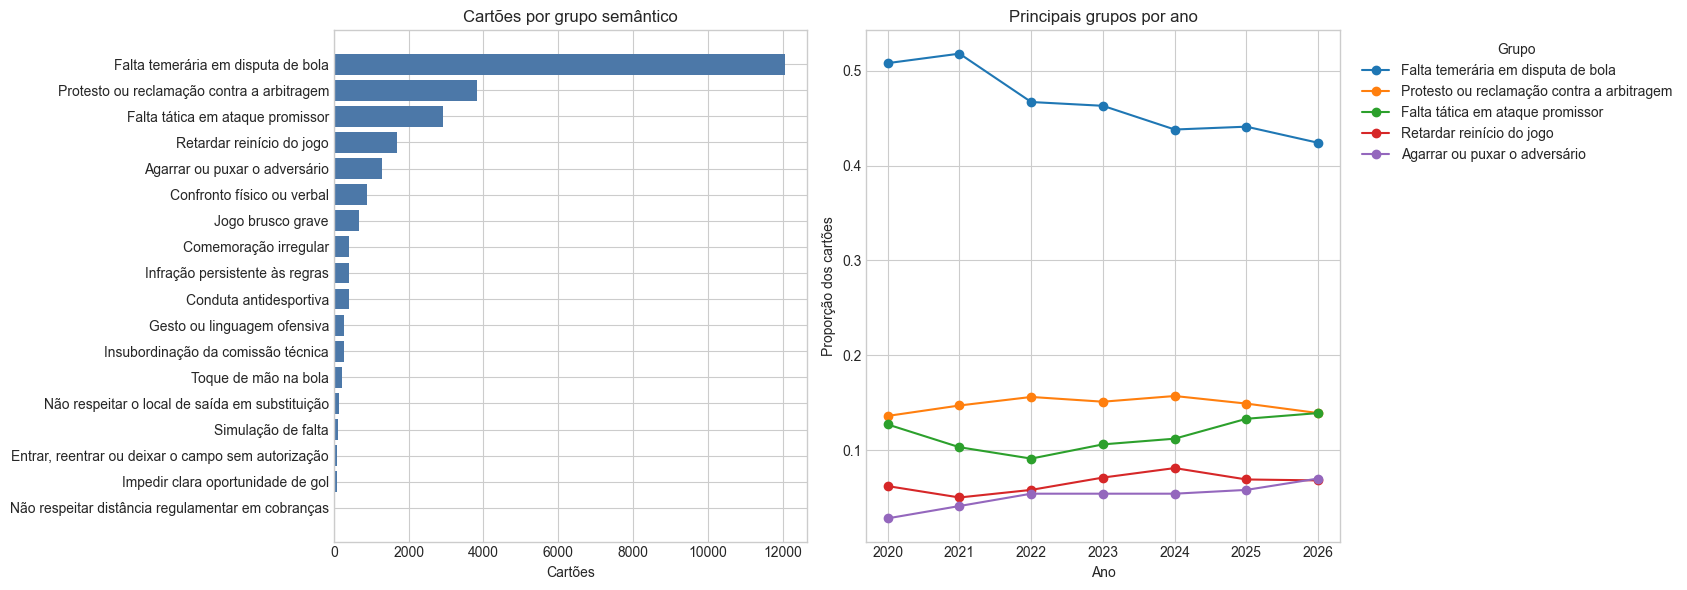

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_card_summary = card_group_summary.sort_values("n_events", ascending=True)
axes[0].barh(plot_card_summary["card_reason_group"], plot_card_summary["n_events"], color="#4C78A8")
axes[0].set_title("Cartões por grupo semântico")
axes[0].set_xlabel("Cartões")
axes[0].set_ylabel("")

top_groups = card_group_summary.head(5)["card_reason_group"].tolist()
card_group_by_year[top_groups].plot(ax=axes[1], marker="o")
axes[1].set_title("Principais grupos por ano")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Proporção dos cartões")
axes[1].legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
save_plot(fig, "card_reason_groups_overview.png")
plt.show()

### **8.2 Por Time**

Para cada time, a tabela detalha a contagem de cada grupo semântico nos cartões recebidos. O perfil de motivos reflete o estilo de jogo: times com proporção elevada de "Ataque promissor / falta tática" tendem a ter linha defensiva mais agressiva; times com mais "Protesto contra arbitragem" apresentam comportamento mais reativo.

In [102]:
card_reason_by_team = (
    cards.groupby(["team", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
team_card_totals = cards.groupby("team").size().rename("total_cards")
card_reason_by_team = card_reason_by_team.merge(team_card_totals, on="team", how="left")
card_reason_by_team["pct_team_cards"] = (card_reason_by_team["n_events"] / card_reason_by_team["total_cards"]).round(4)
card_reason_by_team = card_reason_by_team.sort_values(["total_cards", "team", "n_events"], ascending=[False, True, False])

card_reason_top_by_team = (
    card_reason_by_team.sort_values(["team", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("team")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_team.head(30)

,team,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_team_cards
0,Red Bull Bragantino,Falta temerária em disputa de bola,507,489,18,170,999,0.5075
1,Fluminense,Falta temerária em disputa de bola,464,451,13,166,991,0.4682
2,Internacional,Falta temerária em disputa de bola,430,412,18,151,953,0.4512
3,São Paulo,Falta temerária em disputa de bola,411,391,20,148,950,0.4326
4,Palmeiras,Falta temerária em disputa de bola,426,406,20,138,937,0.4546
5,Corinthians,Falta temerária em disputa de bola,465,446,19,162,936,0.4968
6,Athletico Paranaense,Falta temerária em disputa de bola,407,389,18,147,883,0.4609
7,Atlético Mineiro,Falta temerária em disputa de bola,393,379,14,134,877,0.4481
8,Fortaleza Esporte Clube,Falta temerária em disputa de bola,403,383,20,138,851,0.4736
9,Flamengo,Falta temerária em disputa de bola,439,427,12,163,834,0.5264


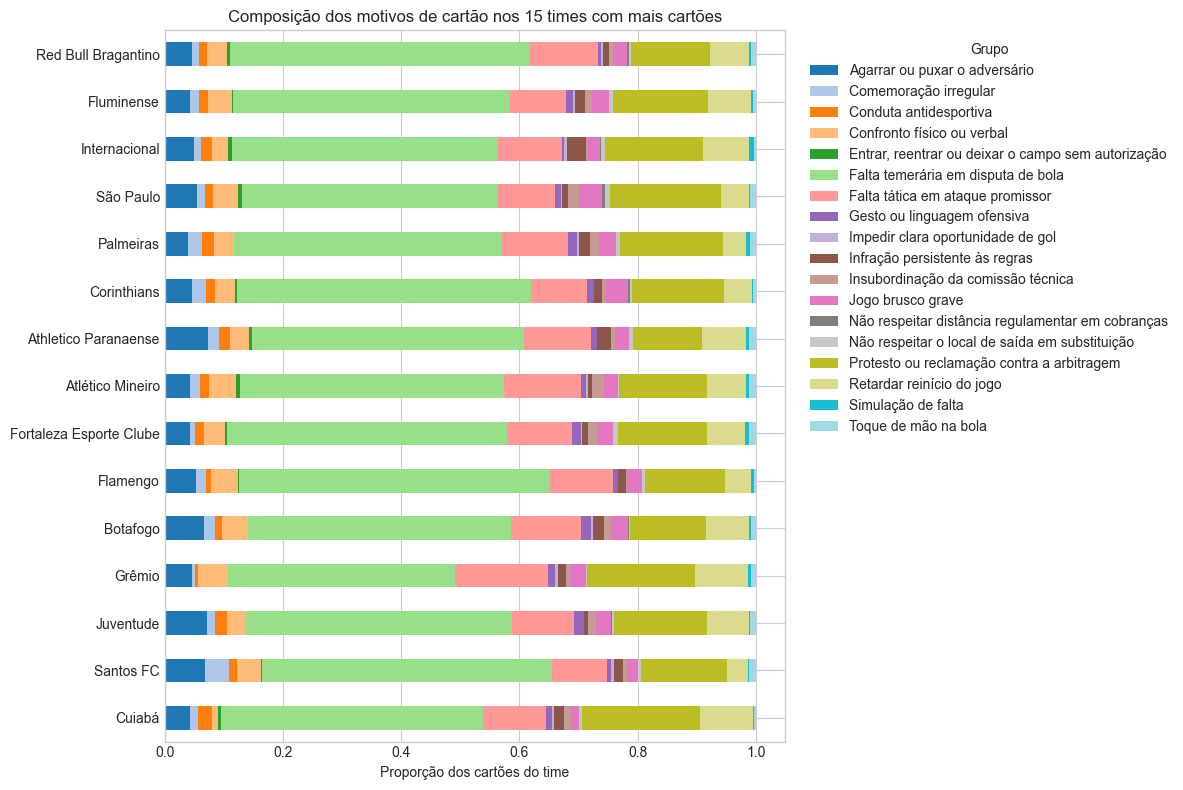

In [103]:
top_card_teams = cards["team"].value_counts().head(TOP_N_TEAMS).index
team_group_plot = pd.crosstab(
    cards.loc[cards["team"].isin(top_card_teams), "team"],
    cards.loc[cards["team"].isin(top_card_teams), "card_reason_group"],
    normalize="index",
).loc[top_card_teams]

fig, ax = plt.subplots(figsize=(12, 8))
team_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_TEAMS} times com mais cartões")
ax.set_xlabel("Proporção dos cartões do time")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_team.png")
plt.show()

### **8.3 Por Árbitro**

A distribuição por árbitro mostra quais tipos de infrações são mais marcados nas partidas de cada árbitro. Árbitros com proporção elevada de "Protesto contra arbitragem" tendem a ser mais rigorosos com reclamações; árbitros com mais "Falta temerária" marcam faltas mais físicas.


In [104]:
card_reason_by_referee = (
    cards.groupby(["arbitro", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
referee_card_totals = cards.groupby("arbitro").size().rename("total_cards")
card_reason_by_referee = card_reason_by_referee.merge(referee_card_totals, on="arbitro", how="left")
card_reason_by_referee["pct_referee_cards"] = (card_reason_by_referee["n_events"] / card_reason_by_referee["total_cards"]).round(4)
card_reason_by_referee = card_reason_by_referee.sort_values(["total_cards", "arbitro", "n_events"], ascending=[False, True, False])

card_reason_top_by_referee = (
    card_reason_by_referee.sort_values(["arbitro", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("arbitro")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_referee.head(30)

,arbitro,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_referee_cards
0,Braulio da Silva Machado,Falta temerária em disputa de bola,519,505,14,102,1178,0.4406
1,Wilton Pereira Sampaio,Falta temerária em disputa de bola,548,530,18,162,1078,0.5083
2,Bruno Arleu de Araujo,Falta temerária em disputa de bola,560,543,17,168,1037,0.5400
3,Ramon Abatti Abel,Falta temerária em disputa de bola,444,432,12,169,993,0.4471
4,Flavio Rodrigues de Souza,Falta temerária em disputa de bola,439,420,19,140,921,0.4767
5,Raphael Claus,Falta temerária em disputa de bola,503,481,22,152,911,0.5521
6,Anderson Daronco,Falta temerária em disputa de bola,456,439,17,145,909,0.5017
7,Felipe Fernandes de Lima,Falta temerária em disputa de bola,347,336,11,142,847,0.4097
8,Savio Pereira Sampaio,Falta temerária em disputa de bola,354,345,9,134,829,0.4270
9,Wagner do Nascimento Magalhaes,Falta temerária em disputa de bola,406,389,17,140,799,0.5081


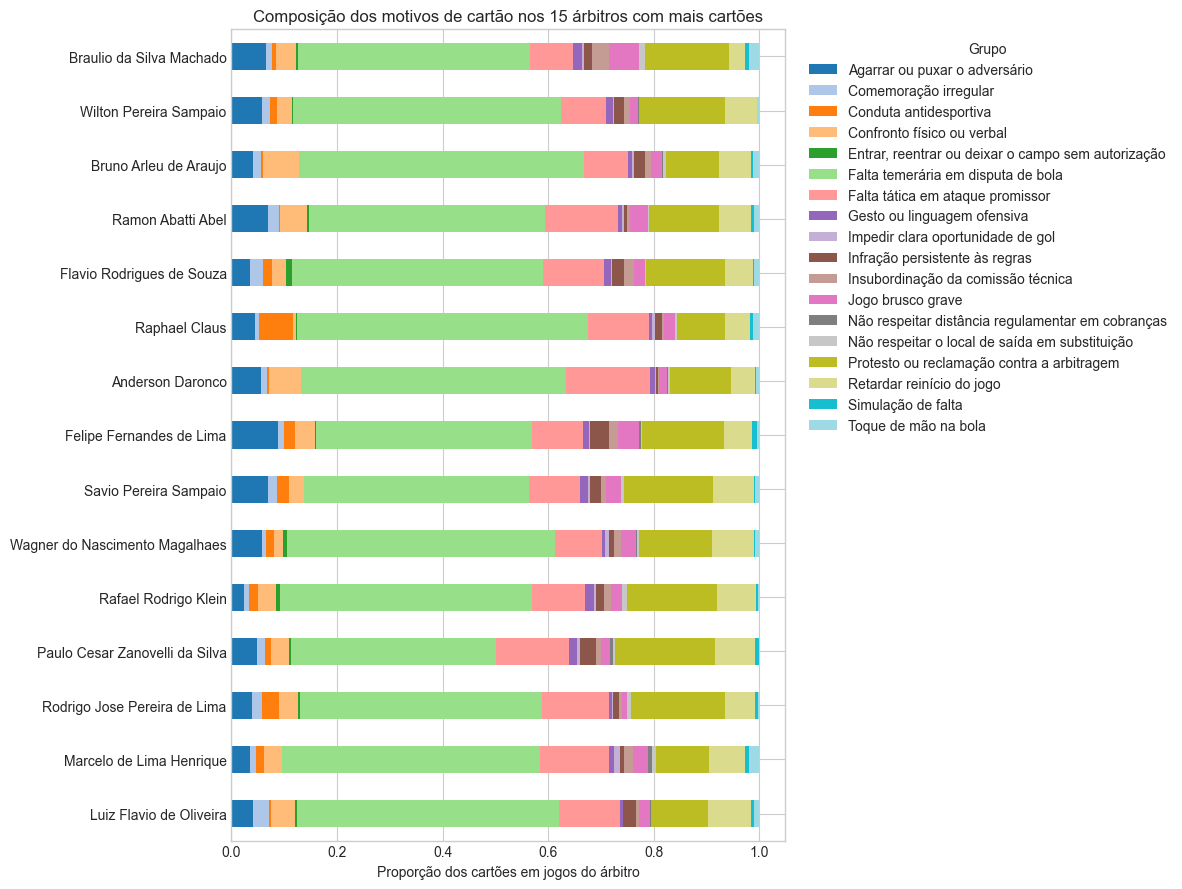

In [105]:
top_card_referees = cards["arbitro"].value_counts().head(TOP_N_REFEREES).index
referee_group_plot = pd.crosstab(
    cards.loc[cards["arbitro"].isin(top_card_referees), "arbitro"],
    cards.loc[cards["arbitro"].isin(top_card_referees), "card_reason_group"],
    normalize="index",
).loc[top_card_referees]

fig, ax = plt.subplots(figsize=(12, 9))
referee_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_REFEREES} árbitros com mais cartões")
ax.set_xlabel("Proporção dos cartões em jogos do árbitro")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_referee.png")
plt.show()

### **8.4 Busca Semântica (Diagnóstico)**

Recupera os textos mais similares a uma consulta livre no espaço de embeddings fine-tunados. Útil para auditar se expressões semanticamente equivalentes ficaram no mesmo grupo e verificar a cobertura dos protótipos.

In [106]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([ENCODE_PREFIX_QUERY + text], normalize_embeddings=True))

def semantic_search_cards(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query(query)
    similarities = cosine_similarity(query_embedding, card_embeddings).ravel()
    result = card_text_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "similarity", "n_events", "card_reason_group", "bertopic_topic", "text_for_embedding",
    ]].head(top_k)

semantic_search_cards("reclamação contra arbitragem", top_k=10)

,similarity,n_events,card_reason_group,bertopic_topic,text_for_embedding
4485,0.917319,1,Protesto ou reclamação contra a arbitragem,-1,Reclamar com arbitragem.
955,0.909394,4,Protesto ou reclamação contra a arbitragem,-1,Reclamação contra a arbitragem.
107,0.901274,30,Protesto ou reclamação contra a arbitragem,-1,Reclamar das decisões da arbitragem
1066,0.900900,3,Protesto ou reclamação contra a arbitragem,-1,Reclamar das marcações da arbitragem
2156,0.898229,2,Protesto ou reclamação contra a arbitragem,-1,Reclamação com a arbitragem com palavras
4499,0.897968,1,Protesto ou reclamação contra a arbitragem,-1,Reclamação contra a decisão da arbitragem
4592,0.894857,1,Protesto ou reclamação contra a arbitragem,-1,Reclamar contra decisões da arbitragem
48,0.893855,67,Protesto ou reclamação contra a arbitragem,-1,Reclamar contra as decisões da arbitragem
447,0.888547,7,Protesto ou reclamação contra a arbitragem,35,Por reclamação contra a arbitragem.
4002,0.886919,1,Protesto ou reclamação contra a arbitragem,35,Por reclamacao contra arbitragem.


## **9. Motivos de Acréscimos e Detecção de VAR**

Os motivos de acréscimos são tratados separadamente dos cartões. O único objetivo analítico é detectar se há menção ao VAR na justificativa de acréscimo registrada pelo árbitro.

A detecção é **léxica** — expressões regulares sobre o texto normalizado. Esta abordagem é suficiente porque a presença de VAR é um sinal fortemente textual: árbitros mencionam explicitamente "VAR", "AVAR", "revisão de vídeo" etc. quando o protocolo é ativado.

### **9.1 Exploração dos Textos de Atraso (BERTopic)**

BERTopic aplicado ao corpus de textos de atraso para mapear a diversidade temática. Esta etapa é exploratória — os clusters não são usados na detecção de VAR.

In [107]:
delay_text_counts = (
    delays[delays[DELAY_TEXT_COLUMN].ne("n/a")]
    .groupby("delay_reason_key")
    .agg(
        text_for_embedding=(DELAY_TEXT_COLUMN, "first"),
        n_games=(DELAY_TEXT_COLUMN, "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
    .sort_values("n_games", ascending=False)
    .reset_index(drop=True)
)
delay_text_counts.head(25)

,delay_reason_key,text_for_embedding,n_games,first_year,last_year
0,acrescimos devido as substituicoes e atendimento medico aos atletas,Acréscimos devido as substituições e atendimento médico aos atletas.,30,2020,2026
1,acrescimos devido substituicoes e transporte de atletas lesionados,Acréscimos devido substituições e transporte de atletas lesionados.,22,2020,2021
2,acrescimos devido a substituicoes atendimento medico e retirada de atletas supostamente lesionados do campo de jogo,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo.",14,2021,2023
3,acrescimos devido a substituicoes e atendimento de atletas supostamente lesionados,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .,13,2020,2025
4,acrescimos devido substituicoes atendimento medico aos atletas lesionados e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas.",13,2021,2025
5,acrescimos devido as substituicoes atendimento medico aos atletas e checagem do var,"Acréscimos devido as substituições, atendimento médico aos atletas e checagem do var.",12,2020,2022
6,nao houve atraso no inicio e reinicio de jogo acrescimos motivados por substituicoes e atendimento a jogadores supostamente lesionados,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.,11,2021,2025
7,acrescimos devido substituicoes atendimento medico aos atletas lesionados checagens do var e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas.",11,2023,2024
8,acrescimos devido substituicoes atendimento medico aos atletas lesionados e checagens do var,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e checagens do var.",11,2020,2022
9,acrescimos devido paralisacoes substituicoes e atendimento de atletas supostamente lesionados,"Acréscimos devido paralisações, substituições e atendimento de atletas supostamente lesionados.",10,2020,2024


In [108]:
delay_texts = delay_text_counts["text_for_embedding"].tolist()
delay_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in delay_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
delay_embeddings = np.asarray(delay_embeddings)
print(f"Embeddings de atrasos/acréscimos: {delay_embeddings.shape}")

Batches: 100%|██████████| 59/59 [01:09<00:00,  1.18s/it]

Embeddings de atrasos/acréscimos: (3764, 1024)


In [109]:
delay_topic_model = make_topic_model(DELAY_MIN_TOPIC_SIZE)
delay_topics, _ = delay_topic_model.fit_transform(delay_texts, embeddings=delay_embeddings)
delay_text_counts["bertopic_topic"] = delay_topics

delay_text_counts_for_summary = delay_text_counts.rename(columns={"n_games": "n_events"})
delay_topic_summary = build_topic_summary(delay_topic_model, delay_text_counts_for_summary, "bertopic_topic")
delay_topic_summary.head(20)

,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,879,0_substituições_acréscimos_atendimento_atletas,"[substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições, substituições atendimento, atletas supostamente]","[Acréscimos para substituições e atendimento a atletas supostamente lesionados., Acréscimos devido as substituições e atendimento de atletas supostamente lesionados., Acréscimos devido à substituições e atendimento à...",879,1458,"substituições, acréscimos, atendimento, atletas, lesionados, supostamente, supostamente lesionados, acréscimos substituições"
1,1,426,1_homenagem_silêncio_respeitado_silêncio homenagem,"[homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos, substituições, covid]","[Acréscimos devido a substituições, retirada de atletas supostamente lesionados do campo de jogo, reposição de bola e checagem do var. foi respeitado um minuto de silêncio em homenagem póstuma as vítimas do covid-19....",426,621,"homenagem, silêncio, respeitado, silêncio homenagem, homenagem póstuma, póstuma, respeitado silêncio, acréscimos"
2,-1,422,-1_atraso_ilustre_torcedor_fluminense,"[atraso, ilustre, torcedor, fluminense, entrada, informo, substituições, flamengo, acréscimos, lesionados]","[Informo que a equipe do sport clube do recife, retornou do intervalo de jogo com atraso de dois minutos, por este motivo o segundo tempo de jogo iniciou com atraso de um minuto. acréscimos motivados por atendimento ...",422,598,outliers
3,2,370,2_não_não houve_houve_não houve atraso,"[não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos, atrasos acréscimos, houve atraso acréscimos]","[Não houve atraso. acréscimos por substituições e retirada de atletas supostamente lesionados., Não houve atraso. acréscimos devido a substituições, atendimento de atletas supostamente lesionados e reposição de bola....",370,542,"não, não houve, houve, não houve atraso, houve atraso, acréscimos, substituições, atrasos"
4,3,282,3_não houve_não_houve_homenagem,"[não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma, homenagem póstuma, respeitado]","[Não houve atrasos. acréscimos devido as substituições, retirada de atletas supostamente lesionados e reposição de bola.informo que antes da partida foi respeitado um minuto de silêncio em homenagem póstuma as vitima...",282,451,"não houve, não, houve, homenagem, não houve atraso, silêncio, houve atraso, póstuma"
5,4,255,4_homenagem_silêncio_covid_respeitado,"[homenagem, silêncio, covid, respeitado, 19, covid 19, silêncio homenagem, acréscimos, 19 acréscimos, substituições]","[Foi respeitado 1 minuto de silêncio em homenagem as vitimas da covid 19.acréscimos devido a substituições e atendimento de atletas supostamente lesionados., Foi respeitado 1 minuto de silêncio de homenagem as vítima...",255,341,"homenagem, silêncio, covid, respeitado, 19, covid 19, silêncio homenagem, acréscimos"
6,6,188,6_primeiro_segundo_primeiro segundo_acréscimos primeiro,"[primeiro, segundo, primeiro segundo, acréscimos primeiro, segundo paralisações substituições, segundo paralisações, substituições, lesionados, atendimento, paralisações substituições]","[Acréscimos de 6 minutos no primeiro tempo, e 6 minutos no segundo tempo devido a paralisações, substituições, atendimento a atletas lesionados e checagem do var., Acréscimos de 6 minutos no primeiro tempo, e 7 minut...",188,277,"primeiro, segundo, primeiro segundo, acréscimos primeiro, segundo paralisações substituições, segundo paralisações, substituições, lesionados"
7,5,202,5_atraso_entrada_reinício_acréscimos,"[atraso, entrada, reinício, acréscimos, equipes, substituições, ambas, segundo, ambas equipes, atletas]",[Informo que ambas as equipes atrasaram em 5 minutos sua entrada em campo para a execução do protocolo de entrada e hino. em virtude d

In [110]:
delay_topic_examples = top_examples_by_topic(
    delay_text_counts.rename(columns={"n_games": "n_events"}),
    "bertopic_topic",
    top_n=5,
).rename(columns={"n_events": "n_games"})
delay_topic_examples.head(30)

,bertopic_topic,n_games,text_for_embedding
0,-1,2,"- acrescimos devido substituições , retirada de atletas do campo e revisões na ara.- concedido um minuto de silencio em homenagem postuma ao sr denis leitao de castro."
1,-1,2,"Acréscimos em função de atendimento a atletas supostamente lesionados, entrada da maca, substituições, checagem do var e comemorações de gols. informo que a equipe do bahia retornou para reinicio do jogo (segundo tem..."
2,-1,2,* acrescimos devido substituições e retirada de atletas do campo de jogo.* concedido um minuto de silencio em homenagem postuma as vitimas da covid19.
3,-1,2,Acrescimos devido substituições e retirada de atletas do campo de jogo. foi concedido um minuto de silencio em homenagem postumas a diego armando maradona e as vitimas da covid 19.
4,-1,2,Acréscimos devidos as substituições e atendimentos médico aos atletas lesionados.informo que a partida inicio com 2 minutos de atraso devido ao atraso de são paulo futebol clube de 3 minutos e da equipe saf botafogo ...
5,0,30,Acréscimos devido as substituições e atendimento médico aos atletas.
6,0,22,Acréscimos devido substituições e transporte de atletas lesionados.
7,0,14,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo."
8,0,13,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .
9,0,13,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas."


### **9.2 Detecção Léxica de VAR**

Os padrões cobrem siglas institucionais (`VAR`, `AVAR`, `VOR`, `ARA`), variações descritivas (`árbitro de vídeo`), termos de processo (`checagem`, `revisão`, `review`) e referências a infraestrutura (`monitor`, `cabine`). O sinal `monitor_cabine` é o mais ambíguo — "monitor" pode aparecer em contextos não-VAR.

In [111]:
VAR_SIGNAL_PATTERNS = {
    "var": r"\bvar\b",
    "avar": r"\bavar\b",
    "vor": r"\bvor\b|sala\s+vor",
    "ara": r"\bara\b",
    "arbitro_de_video": r"arbitro\s+de\s+video|arbitragem\s+de\s+video|video\s+arbitro",
    "checagem": r"checag(?:em|ens)|checando|checar",
    "revisao": r"revis(?:ao|oes|ar|ado|ada)|review",
    "monitor_cabine": r"\bmonitor\b|\bcabine\b",
}

def detect_var_signals(text: str) -> tuple[bool, str]:
    normalized = normalize_text(text)
    matches = [name for name, pattern in VAR_SIGNAL_PATTERNS.items() if re.search(pattern, normalized)]
    return bool(matches), ", ".join(matches)

var_detection = delays[DELAY_TEXT_COLUMN].apply(detect_var_signals)
delays["var_used"] = var_detection.map(lambda item: item[0])
delays["var_signal"] = var_detection.map(lambda item: item[1])

var_summary = pd.Series({
    "games_total": len(delays),
    "games_with_var_signal": int(delays["var_used"].sum()),
    "pct_with_var_signal": round(delays["var_used"].mean(), 4),
})
var_summary

games_total              5663.0000
games_with_var_signal    2031.0000
pct_with_var_signal         0.3586
dtype: float64

In [112]:
signal_counts = {}
for signal_name, pattern in VAR_SIGNAL_PATTERNS.items():
    signal_counts[signal_name] = delays[DELAY_TEXT_COLUMN].apply(
        lambda t, p=pattern: bool(re.search(p, normalize_text(str(t))))
    ).sum()

signal_dist = pd.Series(signal_counts, name='partidas').sort_values(ascending=False)
print('Frequência de cada sinal VAR:')
print(signal_dist.to_string())

only_monitor = (
    delays[delays['var_signal'].eq('monitor_cabine')]
    [[DELAY_TEXT_COLUMN, 'year']]
    .drop_duplicates(DELAY_TEXT_COLUMN)
    .sort_values('year')
    .reset_index(drop=True)
)
print(f'\nTextos ativados exclusivamente por monitor_cabine: {len(only_monitor)}')
print('Revisar manualmente para estimar precisão do detector neste sinal.')
only_monitor.head(15)

Frequência de cada sinal VAR:
var                 1745
checagem            1512
revisao              561
ara                  136
arbitro_de_video      79
vor                   48
monitor_cabine        36
avar                   2

Textos ativados exclusivamente por monitor_cabine: 1
Revisar manualmente para estimar precisão do detector neste sinal.


,delay_reason_clean,year
0,"Não houve atraso. os acréscimos foram dados por reposição da bola em jogo, gols, substituições atendimento ao goleiro mandante, tempo de cabine e retirada de atletas para atendimento.",2023


### **9.3 Evolução do VAR por Ano**

Proporção de partidas com sinal de VAR detectado por ano. Espera-se crescimento após a implementação do sistema no Campeonato Brasileiro a partir de 2019.

In [113]:
delay_var_by_year = (
    delays.groupby("year")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
    )
    .reset_index()
)
delay_var_by_year["pct_with_var_signal"] = (
    delay_var_by_year["games_with_var_signal"] / delay_var_by_year["games"]
).round(4)
delay_var_by_year

,year,games,games_with_var_signal,pct_with_var_signal
0,2020,880,211,0.2398
1,2021,882,375,0.4252
2,2022,882,340,0.3855
3,2023,882,347,0.3934
4,2024,882,325,0.3685
5,2025,882,326,0.3696
6,2026,373,107,0.2869


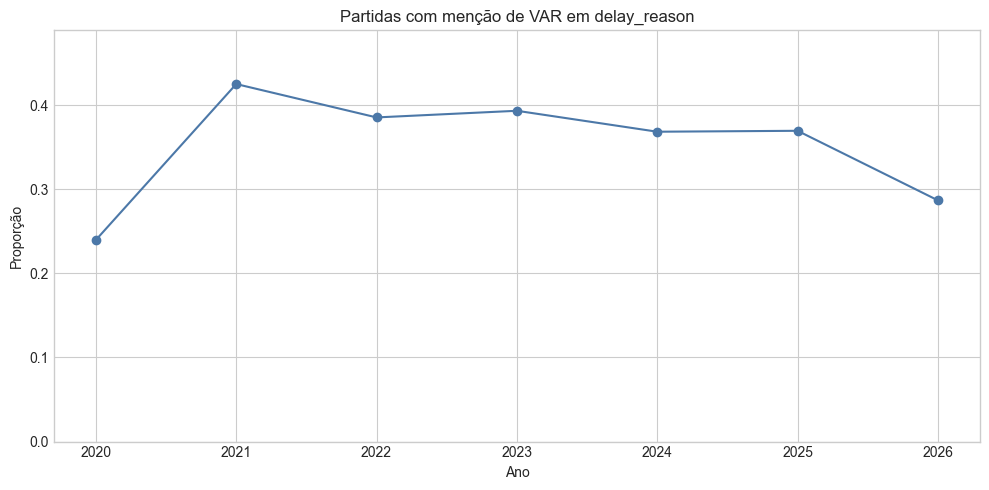

In [114]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(delay_var_by_year["year"], delay_var_by_year["pct_with_var_signal"], marker="o", color="#4C78A8")
ax.set_title("Partidas com menção de VAR em delay_reason")
ax.set_xlabel("Ano")
ax.set_ylabel("Proporção")
ax.set_ylim(0, max(0.05, delay_var_by_year["pct_with_var_signal"].max() * 1.15))
plt.tight_layout()
save_plot(fig, "var_mentions_by_year.png")
plt.show()

In [115]:
var_examples = (
    delays[delays["var_used"]]
    .sort_values(["year", "round", "game_number"])
    [["year", "round", "home_team", "away_team", "arbitro", "var_signal", DELAY_TEXT_COLUMN]]
    .head(25)
)
var_examples

,year,round,home_team,away_team,arbitro,var_signal,delay_reason_clean
10,2020,1,Santos FC,Red Bull Bragantino,Ricardo Marques Ribeiro,"var, checagem",Não houve atraso no inicio e reinicio do jogo. foi cumprido a diretriz técnica operacional da cbf de entrada das equipes 05 (cinco) minutos antes do jogo para equipe local (15:55) e 04 (quatro) minutos antes do jogo ...
19,2020,1,Sport Recife,Ceará,Edina Alves Batista,"var, checagem","Não houve atraso. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (20:55) e 4 (quatro) minutos antes do jogo para equipe visitante (20:56)..."
25,2020,1,Fortaleza Esporte Clube,Athletico Paranaense,Braulio da Silva Machado,"var, checagem","Não houve atraso no início e reinício de jogo. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (18:55) e 4 (quatro) minutos antes do jogo ..."
74,2020,2,Vasco da Gama,Sport Recife,Rodolpho Toski Marques,"var, revisao","Não houve atraso no início e reinício de jogo.foram acrescidos 2 minutos no primeiro tempo e 8 minutos no segundo tempo devido as substituições, reposição de bola em jogo, avaliação médica dos atletas supostamente le..."
83,2020,2,Atlético Mineiro,Corinthians,Wagner do Nascimento Magalhaes,var,"Não houve atraso no início e reinício da partida.acréscimos devido substituições,atendimento à atletas supostamente lesionados,reposição de bola em jogo e var.houve 01 minuto de silêncio em homenagem às vitimas do co..."
92,2020,2,Athletico Paranaense,Goiás,Diego Pombo Lopez,"var, checagem","Acréscimos no primeiro tempo devido a atendimento e retirada pela ambulância do atleta número 55 do athlético e também por checagens do var. acréscimos no segundo tempo devido a substituições, retirada de atletas sup..."
98,2020,2,Atlético,Flamengo,Luiz Flavio de Oliveira,"var, checagem","Não houve atrasos.acréscimos motivados por, atendimento médico, substituições, reposição de bola em jogo e checagem do var.informo que na relação nominal de atletas da equipe atletico cg, constava que o uniforme do g..."
120,2020,3,Fluminense,Internacional,Raphael Claus,"var, revisao","Não houve atraso no início e reinício da partida. houve acréscimos no primeiro e no segundo tempo de partida, devido as substituições, revisões do var, reposições de bola em jogo e atendimentos aos atletas supostamen..."
126,2020,3,Santos FC,Athletico Paranaense,Anderson Daronco,"var, checagem","Acréscimos de 4 minutos no primeiro tempo e 5 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var."
132,2020,3,Esporte Clube Bahia,Red Bull Bragantino,Felipe Fernandes de Lima,"var, checagem","Acréscimos devido as paralisações para retirada de atletas supostamente lesionados do campo de jogo, substituições e recuperação de tempo perdido por checagem do var.informo que foi respeitado um minuto de silêncio e..."


### **9.4 VAR por Time e Árbitro**

Para times: contagem sobre partidas em que o time aparece como mandante ou visitante — o mesmo jogo é contado para ambos. Para árbitros: contagem sobre as partidas apitadas. Em ambos os casos, `var_used` indica presença de sinal textual de VAR no campo de atraso, não validação externa do protocolo.

In [116]:
def most_common_non_empty(values: pd.Series) -> str:
    cleaned = values.astype(str).str.strip()
    cleaned = cleaned[cleaned.ne("")]
    if cleaned.empty:
        return ""
    return cleaned.value_counts().idxmax()

delay_home_games = delays.rename(columns={"home_team": "team", "away_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_away_games = delays.rename(columns={"away_team": "team", "home_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_team_games = pd.concat([delay_home_games, delay_away_games], ignore_index=True)

delay_var_by_team = (
    delay_team_games.groupby("team")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_team["pct_with_var_signal"] = (
    delay_var_by_team["games_with_var_signal"] / delay_var_by_team["games"]
).round(4)
delay_var_by_team = delay_var_by_team.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_team.head(30)

,team,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Red Bull Bragantino,456,174,"var, checagem",0.3816
1,Flamengo,443,189,"var, checagem",0.4266
2,Corinthians,442,194,"var, checagem",0.4389
3,Fluminense,442,173,"var, checagem",0.3914
4,Palmeiras,426,196,"var, checagem",0.4601
5,Internacional,417,177,"var, checagem",0.4245
6,Athletico Paranaense,398,170,"var, checagem",0.4271
7,São Paulo,396,207,"var, checagem",0.5227
8,Atlético Mineiro,396,146,"var, checagem",0.3687
9,Fortaleza Esporte Clube,368,158,"var, checagem",0.4293


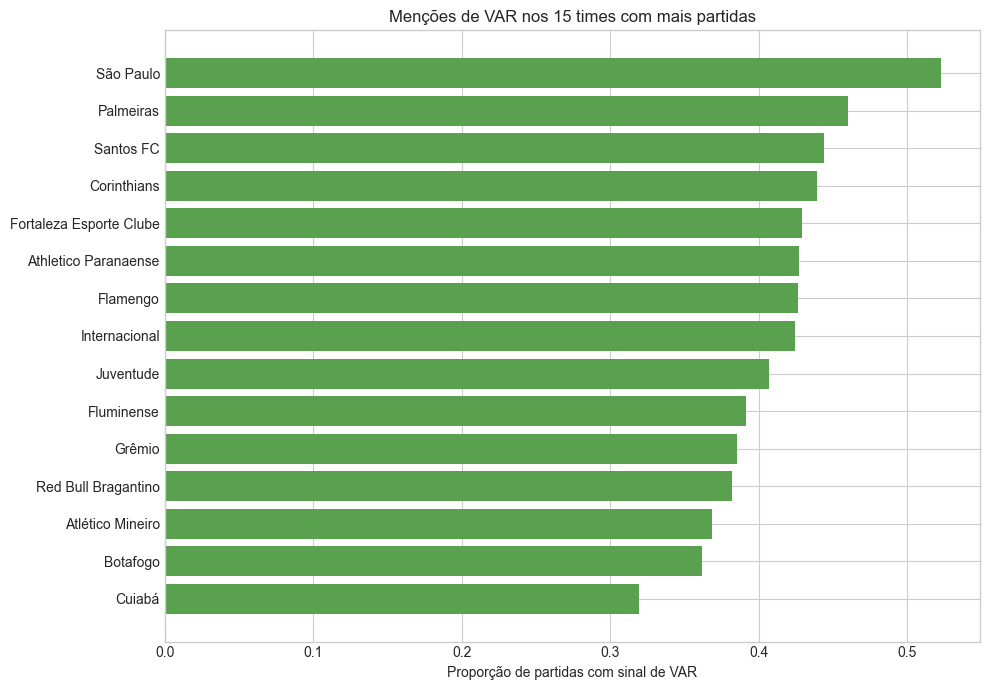

In [117]:
top_var_teams = delay_var_by_team.head(TOP_N_TEAMS).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_var_teams["team"], top_var_teams["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_TEAMS} times com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_team.png")
plt.show()

In [118]:
delay_var_by_referee = (
    delays.groupby("arbitro")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_referee["pct_with_var_signal"] = (
    delay_var_by_referee["games_with_var_signal"] / delay_var_by_referee["games"]
).round(4)
delay_var_by_referee = delay_var_by_referee.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_referee.head(30)

,arbitro,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Anderson Daronco,255,83,"var, checagem",0.3255
1,Raphael Claus,243,80,"var, checagem",0.3292
2,Ramon Abatti Abel,233,102,"var, checagem",0.4378
3,Wilton Pereira Sampaio,223,103,"var, checagem",0.4619
4,Braulio da Silva Machado,222,131,"var, checagem",0.5901
5,Flavio Rodrigues de Souza,217,94,"var, checagem",0.4332
6,Bruno Arleu de Araujo,205,87,"var, checagem",0.4244
7,Savio Pereira Sampaio,190,80,"var, checagem",0.4211
8,Marcelo de Lima Henrique,175,67,"var, checagem",0.3829
9,Wagner do Nascimento Magalhaes,165,59,"var, checagem",0.3576


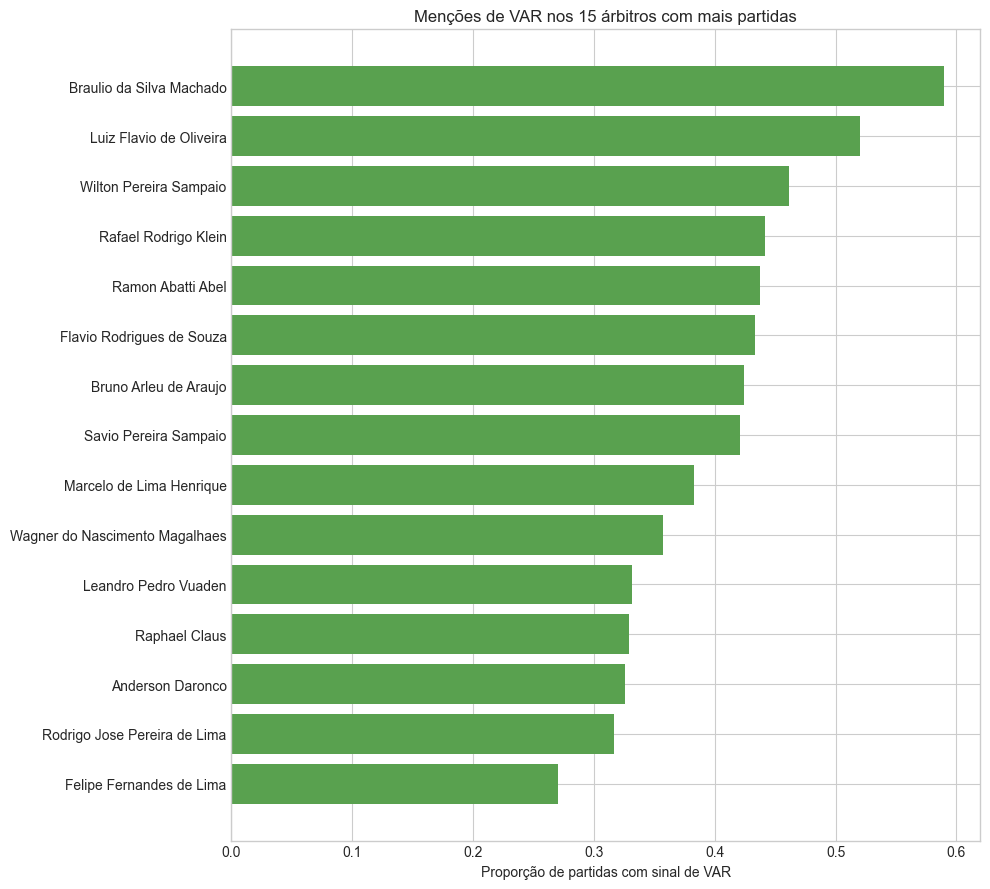

In [119]:
top_var_referees = delay_var_by_referee.head(TOP_N_REFEREES).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_var_referees["arbitro"], top_var_referees["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_REFEREES} árbitros com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_referee.png")
plt.show()

## **10. Salvamento dos Artefatos**

Arquivos gerados em `data/processed/semantic_reasons/card_reasons/`:

- `card_reasons_with_labels.csv` — dataset completo com grupo semântico por cartão
- `card_reason_group_summary.csv` — distribuição de eventos por grupo
- `card_reason_by_team.csv` / `card_reason_by_referee.csv` — tabelas analíticas
- `card_reason_outros_audit.csv` — textos não atribuídos (diagnóstico; vazio se cobertura total)

Visualizações em `viz/`.

In [120]:
outros_audit = (
    cards[cards["card_reason_group"].eq("Outros")]
    .groupby(CARD_TEXT_COLUMN)
    .size()
    .reset_index(name="n_events")
    .sort_values("n_events", ascending=False)
)

card_topic_summary_path = CARD_OUTPUT_DIR / "card_bertopic_topic_summary.csv"
card_topic_examples_path = CARD_OUTPUT_DIR / "card_bertopic_topic_examples.csv"
card_unique_topics_path = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
card_labeled_path = CARD_OUTPUT_DIR / "card_reasons_with_labels.csv"
card_group_summary_path = CARD_OUTPUT_DIR / "card_reason_group_summary.csv"
card_group_by_year_path = CARD_OUTPUT_DIR / "card_reason_group_by_year.csv"
card_group_by_type_path = CARD_OUTPUT_DIR / "card_reason_group_by_card_type.csv"
card_reason_by_team_path = CARD_OUTPUT_DIR / "card_reason_by_team.csv"
card_reason_top_by_team_path = CARD_OUTPUT_DIR / "card_reason_top_by_team.csv"
card_reason_by_referee_path = CARD_OUTPUT_DIR / "card_reason_by_referee.csv"
card_reason_top_by_referee_path = CARD_OUTPUT_DIR / "card_reason_top_by_referee.csv"
outros_audit_path = CARD_OUTPUT_DIR / "card_reason_outros_audit.csv"

delay_topic_summary_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_summary.csv"
delay_topic_examples_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_examples.csv"
delay_unique_topics_path = DELAY_OUTPUT_DIR / "delay_reason_unique_topics.csv"
delay_labeled_path = DELAY_OUTPUT_DIR / "delay_reasons_with_var.csv"
delay_var_by_year_path = DELAY_OUTPUT_DIR / "delay_var_by_year.csv"
delay_var_by_team_path = DELAY_OUTPUT_DIR / "delay_var_by_team.csv"
delay_var_by_referee_path = DELAY_OUTPUT_DIR / "delay_var_by_referee.csv"

card_topic_summary.to_csv(card_topic_summary_path, index=False)
card_topic_examples.to_csv(card_topic_examples_path, index=False)
card_text_counts.to_csv(card_unique_topics_path, index=False)
cards.to_csv(card_labeled_path, index=False)
card_group_summary.to_csv(card_group_summary_path, index=False)
card_group_by_year.to_csv(card_group_by_year_path)
card_group_by_type.to_csv(card_group_by_type_path)
card_reason_by_team.to_csv(card_reason_by_team_path, index=False)
card_reason_top_by_team.to_csv(card_reason_top_by_team_path, index=False)
card_reason_by_referee.to_csv(card_reason_by_referee_path, index=False)
card_reason_top_by_referee.to_csv(card_reason_top_by_referee_path, index=False)
outros_audit.to_csv(outros_audit_path, index=False)

delay_topic_summary.to_csv(delay_topic_summary_path, index=False)
delay_topic_examples.to_csv(delay_topic_examples_path, index=False)
delay_text_counts.to_csv(delay_unique_topics_path, index=False)
delays.to_csv(delay_labeled_path, index=False)
delay_var_by_year.to_csv(delay_var_by_year_path, index=False)
delay_var_by_team.to_csv(delay_var_by_team_path, index=False)
delay_var_by_referee.to_csv(delay_var_by_referee_path, index=False)

output_paths = [
    card_topic_summary_path,
    card_topic_examples_path,
    card_unique_topics_path,
    card_labeled_path,
    card_group_summary_path,
    card_group_by_year_path,
    card_group_by_type_path,
    card_reason_by_team_path,
    card_reason_top_by_team_path,
    card_reason_by_referee_path,
    card_reason_top_by_referee_path,
    outros_audit_path,
    delay_topic_summary_path,
    delay_topic_examples_path,
    delay_unique_topics_path,
    delay_labeled_path,
    delay_var_by_year_path,
    delay_var_by_team_path,
    delay_var_by_referee_path,
]

print("Arquivos salvos:")
for output_path in output_paths:
    print(f"  {output_path}")

Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_examples.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reasons_with_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_year.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_card_type.csv
  /Users/gcarninatto/D